<a href="https://colab.research.google.com/github/SabaFeizi/Machine-Learning-Fall2026/blob/main/Perceptron_Pima_Diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# 🩺 آیا این بیمار دیابت دارد؟
### حل یک مسئلهٔ واقعی دسته‌بندی با پرسپترون و الگوریتم Pocket — از دادهٔ خام تا ارزیابی نهایی

فرض کنید در یک درمانگاه کار می‌کنید. پزشکان پروندهٔ **۷۶۸ بیمار** را به شما می‌دهند: نتیجهٔ چند آزمایش ساده (قند خون، فشار خون، BMI و ...) و این‌که آیا آن بیمار دیابت داشته یا نه. سؤال آن‌ها:

> «می‌توانی برنامه‌ای بنویسی که با دیدن آزمایش‌های یک بیمار جدید، بگوید احتمالاً دیابت دارد یا نه؟»

این همان مطالعهٔ موردی اسلایدهای درس است (دیتاست **Pima Indians Diabetes**). در اسلایدها دیدیم که یک **خط ساده** روی دو ویژگی «قند خون» و «BMI» حدود ۷۶٪ بیماران را درست دسته‌بندی می‌کند. در این نوت‌بوک آن خط را **خودمان** با پرسپترون پیدا می‌کنیم!

| قدم | چه کار می‌کنیم؟ | ابزار اصلی |
|---|---|---|
| ۱ | با داده آشنا می‌شویم | `pandas`, `seaborn` |
| ۲ | دادهٔ گمشده‌ای را پیدا می‌کنیم که خودش را «صفر» جا زده! | `pandas` |
| ۳ | داده را به train / validation / test تقسیم می‌کنیم (این بار با `stratify`) | `train_test_split` |
| ۴ | جاهای خالی را پر می‌کنیم و ویژگی‌ها را هم‌مقیاس می‌کنیم | `SimpleImputer`, `StandardScaler` |
| ۵ | پرسپترون را از صفر می‌نویسیم و روی یک دادهٔ جدایی‌پذیر امتحانش می‌کنیم | `numpy` |
| ۶ | روی دادهٔ واقعی پرسپترون سرگردان می‌شود و الگوریتم Pocket نجاتش می‌دهد | `numpy` |
| ۷ | دو آزمایش جالب: نرخ یادگیری و scaling | `numpy` |
| ۸ | مرزهای تصمیم را رسم می‌کنیم | `matplotlib` |
| ۹ | مدل‌ها را با accuracy، precision، recall، F1 و ROC-AUC می‌سنجیم | `sklearn.metrics` |
| ۱۰ | با validation بین مدل‌ها و آستانه‌های تصمیم انتخاب می‌کنیم | `pandas` |
| ۱۱ | نتیجه را با `Perceptron` آمادهٔ `scikit-learn` مقایسه می‌کنیم | `sklearn.linear_model` |
| ۱۲ | پرسپترون چندکلاسه را روی دادهٔ پنگوئن‌ها 🐧 امتحان می‌کنیم | `numpy` |
| ۱۳ | ارزیابی نهایی روی test | همه‌چیز! |

💡 **قرارداد این نوت‌بوک:** خود مدل‌ها (پرسپترون، Pocket و پرسپترون چندکلاسه) را **از صفر** با `numpy` می‌نویسیم تا ببینیم داخلشان چه می‌گذرد. بقیهٔ کارها (خواندن داده، پیش‌پردازش، تقسیم داده، معیارها و نمودارها) را با ابزارهای آمادهٔ `pandas`، `scikit-learn` و `matplotlib` انجام می‌دهیم.

</div>

<div dir="rtl">

## ۰. آماده‌سازی

مثل نوت‌بوک قبلی، فقط چهار کتابخانهٔ اصلی را این‌جا import می‌کنیم و ابزارهای `scikit-learn` را هر جا که لازم شدند.

</div>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")          # a clean look for all plots
plt.rcParams["figure.figsize"] = (7, 4.5)

<div dir="rtl">

## ۱. آشنایی با داده

اولین قدم همیشه یکی است: **داده را باز کن و نگاهش کن!**

</div>

In [ ]:
df = pd.read_csv("data/diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<div dir="rtl">

همهٔ بیماران زنانی با تبار Pima و حداقل ۲۱ سال سن هستند. معنی ستون‌ها:

| ستون | معنی |
|---|---|
| `Pregnancies` | تعداد دفعات بارداری |
| `Glucose` | قند خون، دو ساعت بعد از نوشیدن محلول قند (mg/dL) |
| `BloodPressure` | فشار خون دیاستولیک، همان «فشار پایین» (mmHg) |
| `SkinThickness` | ضخامت چین پوست پشت بازو، معیاری برای چربی بدن (mm) |
| `Insulin` | انسولین خون، دو ساعت بعد از نوشیدن محلول قند (μU/mL) |
| `BMI` | شاخص تودهٔ بدنی: وزن (kg) تقسیم بر مجذور قد (m) |
| `DiabetesPedigreeFunction` | امتیازی برای سابقهٔ دیابت در خانواده |
| `Age` | سن (سال) |
| **`Outcome`** | **۱ = دیابت دارد، ۰ = سالم — همان چیزی که می‌خواهیم پیش‌بینی کنیم (target)** |

</div>

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


<div dir="rtl">

همهٔ ستون‌ها ۷۶۸ مقدار **غیرخالی** دارند. یعنی دادهٔ گمشده نداریم؟ 🤔 زود قضاوت نکنید...

🤔 **قبل از اجرا حدس بزنید:** کمترین فشار خونی که در این داده ثبت شده چند است؟

</div>

In [ ]:
df.describe().round(1)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0
mean,3.8,120.9,69.1,20.5,79.8,32.0,0.5,33.2,0.3
std,3.4,32.0,19.4,16.0,115.2,7.9,0.3,11.8,0.5
min,0.0,0.0,0.0,0.0,0.0,0.0,0.1,21.0,0.0
25%,1.0,99.0,62.0,0.0,0.0,27.3,0.2,24.0,0.0
50%,3.0,117.0,72.0,23.0,30.5,32.0,0.4,29.0,0.0
75%,6.0,140.2,80.0,32.0,127.2,36.6,0.6,41.0,1.0
max,17.0,199.0,122.0,99.0,846.0,67.1,2.4,81.0,1.0


<div dir="rtl">

ردیف `min` را ببینید: کمترین **فشار خون صفر** است! کمترین قند خون، BMI، ضخامت پوست و انسولین هم صفر است.
انسانی که زنده است نمی‌تواند فشار خون یا BMI صفر داشته باشد. این معما را در بخش ۲ حل می‌کنیم.

اول ببینیم چند بیمار دیابتی داریم:

</div>

In [ ]:
print(df["Outcome"].value_counts())
print()
print(df["Outcome"].value_counts(normalize=True).round(3))

Outcome
0    500
1    268
Name: count, dtype: int64

Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


<div dir="rtl">

حدود **۶۵٪ سالم** و **۳۵٪ دیابتی**. به چنین داده‌ای **نامتوازن (imbalanced)** می‌گویند.

⚠️ یک «مدل» تنبل که بدون نگاه کردن به آزمایش‌ها **همیشه** بگوید «سالم»، دقتش ۶۵٪ است! این عدد را به‌عنوان **خط پایه (baseline)** به خاطر بسپارید: هر مدلی که می‌سازیم باید از آن بهتر باشد. در بخش ۹ می‌بینیم چرا دقت (accuracy) به‌تنهایی معیار خوبی نیست.

کدام ویژگی‌ها بیماران دیابتی را از سالم‌ها جدا می‌کنند؟ هیستوگرام چند ویژگی را برای هر کلاس جداگانه رسم می‌کنیم:

</div>

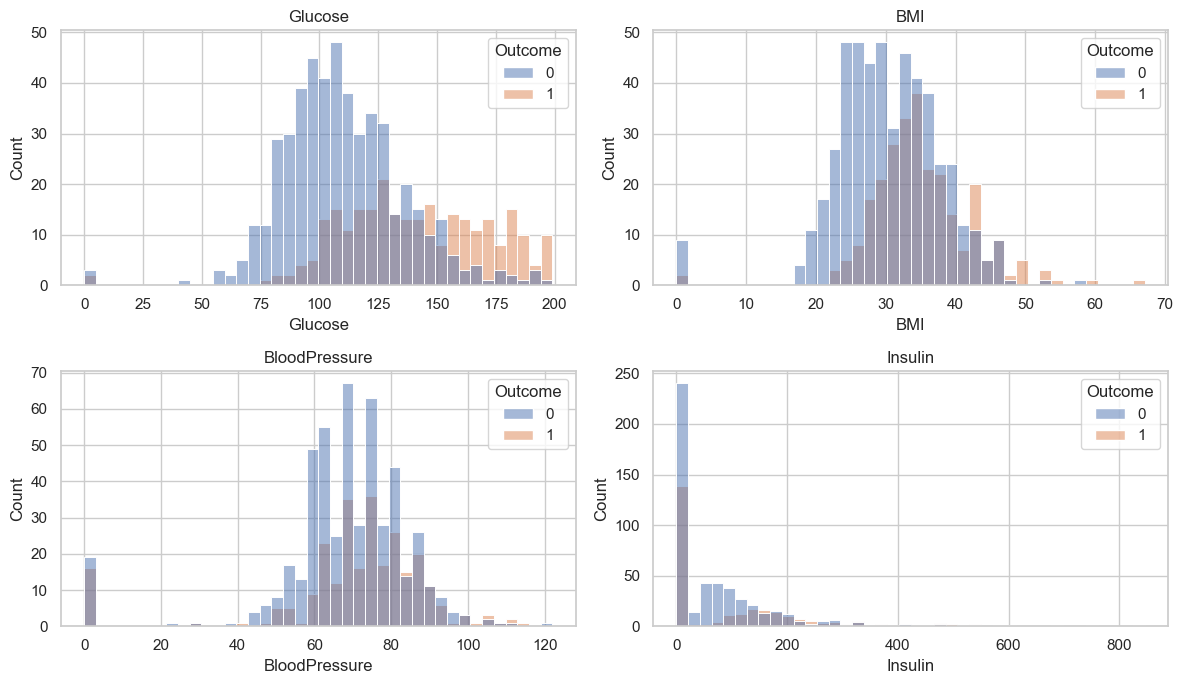

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, column in zip(axes.ravel(), ["Glucose", "BMI", "BloodPressure", "Insulin"]):
    sns.histplot(data=df, x=column, hue="Outcome", bins=40, ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

<div dir="rtl">

دو نکته:

- در `Glucose` و `BMI` توزیع بیماران دیابتی (نارنجی) **به سمت راست** رفته است: قند خون و BMI بالاتر یعنی احتمال دیابت بیشتر. ولی دو توزیع **روی هم افتاده‌اند**؛ پس هیچ مرز ساده‌ای همه را درست جدا نمی‌کند.
- به **میله‌های تنها کنار صفر** نگاه کنید، به‌خصوص در `Insulin`! این‌ها همان صفرهای مشکوک‌اند.

</div>

<div dir="rtl">

## ۲. 🔍 کارآگاه داده: دادهٔ گمشده در لباس مبدل

در این دیتاست هر جا آزمایشی انجام نشده یا ثبت نشده، به‌جای خالی گذاشتن **صفر** نوشته‌اند. برای همین `info()` هیچ جای خالی‌ای نشان نداد. بیایید صفرها را بشماریم:

</div>

In [ ]:
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

(df[zero_columns] == 0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

<div dir="rtl">

چرا `Pregnancies` در این فهرست نیست؟ چون **صفر بار بارداری کاملاً ممکن است!** پیش از تغییر دادن هر مقدار بپرسید: «آیا این عدد در دنیای واقعی ممکن است؟»

حالا صفرهای مشکوک را با `NaN` (علامت استاندارد «مقدار نامعلوم» در `pandas`) جایگزین می‌کنیم.

💡 این کار یک **قاعدهٔ ثابت** است و چیزی از داده «یاد نمی‌گیرد»، پس انجامش قبل از تقسیم داده مشکلی ندارد. ولی پر کردن جاهای خالی با میانه چیزی را از داده یاد می‌گیرد و باید بعد از تقسیم و **فقط روی train** انجام شود (بخش ۴).

</div>

In [ ]:
data = df.copy()
data[zero_columns] = data[zero_columns].replace(0, np.nan)

data.isna().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

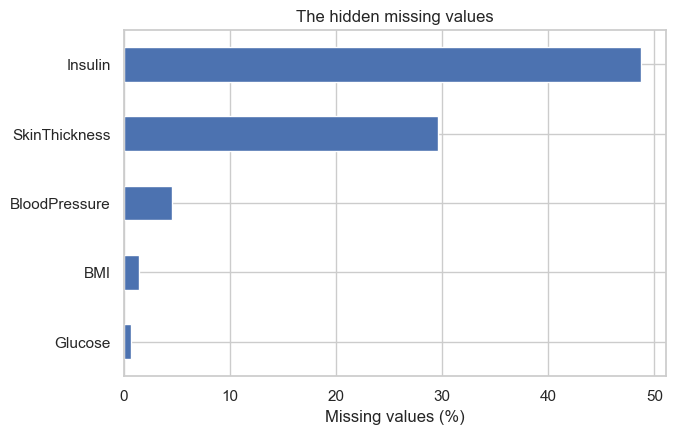

In [ ]:
missing_percent = data.isna().mean() * 100
missing_percent[missing_percent > 0].sort_values().plot.barh()
plt.xlabel("Missing values (%)")
plt.title("The hidden missing values")
plt.show()

<div dir="rtl">

تقریباً **نیمی** از مقادیر `Insulin` و حدود یک‌سوم `SkinThickness` نامعلوم است! اگر همهٔ ردیف‌های ناقص را حذف کنیم:

</div>

In [ ]:
print("All rows:            ", len(data))
print("Rows without any NaN:", len(data.dropna()))

All rows:             768
Rows without any NaN: 392


<div dir="rtl">

نصف بیماران از دست می‌روند! پس مثل نوت‌بوک قبلی جاهای خالی را **پر (impute)** می‌کنیم.

🤔 **برای فکر کردن:** وقتی نصف مقادیر `Insulin` را با یک عدد ثابت پر کنیم، آن ستون هنوز چقدر اطلاعات دارد؟ یک راه دیگر **حذف کامل ستون** است. ما ستون را نگه می‌داریم، ولی در بخش ۱۰ مدلی را هم امتحان می‌کنیم که فقط از دو ویژگی تقریباً کامل `Glucose` و `BMI` استفاده می‌کند.

حالا که صفرهای جعلی کنار رفته‌اند، دو ویژگی مهم را با هم ببینیم (همان نمودار اسلاید ۶):

</div>

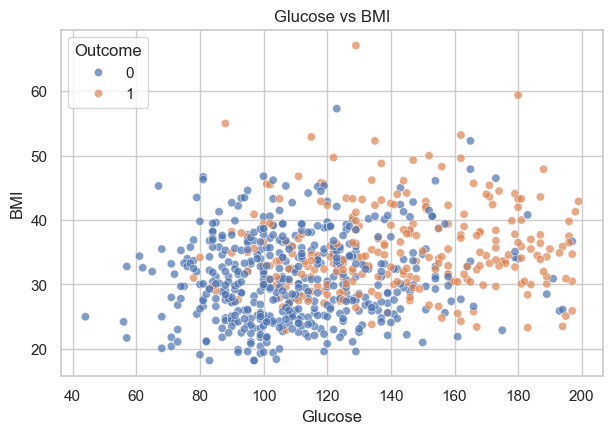

In [ ]:
sns.scatterplot(data=data, x="Glucose", y="BMI", hue="Outcome", alpha=0.7)
plt.title("Glucose vs BMI")
plt.show()

<div dir="rtl">

بیماران دیابتی بیشتر در بالا-راست هستند، ولی دو کلاس حسابی **در هم رفته‌اند**. هیچ خطی نمی‌تواند همهٔ نقطه‌های نارنجی را از آبی جدا کند: داده **جدایی‌پذیر خطی (linearly separable)** نیست.
این را به خاطر بسپارید؛ در بخش ۶ دردسرش را می‌بینیم!

</div>

<div dir="rtl">

## ۳. تقسیم داده: Train / Validation / Test

مثل نوت‌بوک قبلی داده را به سه بخش ۶۰٪، ۲۰٪ و ۲۰٪ تقسیم می‌کنیم: train برای یاد گرفتن، validation برای انتخاب بین مدل‌ها و test فقط برای **یک بار** ارزیابی نهایی.

دو تفاوت با رگرسیون داریم:

۱. **برچسب‌ها را ۱+ و ۱- می‌کنیم** (به‌جای ۱ و ۰)، مثل اسلایدها. با این قرارداد یک نمونه دقیقاً وقتی درست دسته‌بندی شده که <span dir="ltr">$y \cdot g(\mathbf{x}) > 0$</span> باشد؛ یعنی علامت برچسب و علامت امتیاز مدل یکی باشد.

۲. **پارامتر `stratify=y`**: چون فقط ۳۵٪ بیماران دیابتی‌اند، یک تقسیم تصادفی بدشانس ممکن است مثلاً ۲۸٪ دیابتی به test و ۳۹٪ به train بدهد. `stratify` تضمین می‌کند **نسبت کلاس‌ها** در هر سه بخش مثل کل داده باشد.

</div>

In [ ]:
from sklearn.model_selection import train_test_split

features = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]

X = data[features]
y = np.where(data["Outcome"] == 1, 1, -1)      # +1 = diabetic, -1 = healthy

# step 1: keep 20% aside as the final test set
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# step 2: split the remaining 80% into train (60%) and validation (20%)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

print("Train:     ", X_train.shape)
print("Validation:", X_val.shape)
print("Test:      ", X_test.shape)

Train:      (460, 8)
Validation: (154, 8)
Test:       (154, 8)


In [ ]:
print("Share of diabetic patients")
print("  train:     ", round(np.mean(y_train == 1), 3))
print("  validation:", round(np.mean(y_val == 1), 3))
print("  test:      ", round(np.mean(y_test == 1), 3))

Share of diabetic patients
  train:      0.348
  validation: 0.351
  test:       0.351


<div dir="rtl">

در هر سه بخش حدود ۳۵٪ دیابتی داریم. ✅

</div>

<div dir="rtl">

## ۴. پیش‌پردازش: Imputation و Scaling

### ۴.۱ پر کردن جاهای خالی با `SimpleImputer`

همان الگوی آشنای `scikit-learn`: **`fit` فقط روی train** و **`transform` روی هر سه بخش**. جاهای خالی را با **میانهٔ** همان ستون در train پر می‌کنیم.

</div>

In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
imputer.fit(X_train)

# the medians the imputer learned from the training set
pd.Series(imputer.statistics_, index=features)

Pregnancies                   3.000
Glucose                     117.000
BloodPressure                72.000
SkinThickness                30.000
Insulin                     125.000
BMI                          32.400
DiabetesPedigreeFunction      0.389
Age                          29.000
dtype: float64

In [ ]:
X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=features, index=X_train.index)
X_val_imp   = pd.DataFrame(imputer.transform(X_val),   columns=features, index=X_val.index)
X_test_imp  = pd.DataFrame(imputer.transform(X_test),  columns=features, index=X_test.index)

print("Missing values left in train:", X_train_imp.isna().sum().sum())

Missing values left in train: 0


<div dir="rtl">

ببینیم imputation با ستون `Insulin` که نیمی از آن خالی بود چه کرد:

</div>

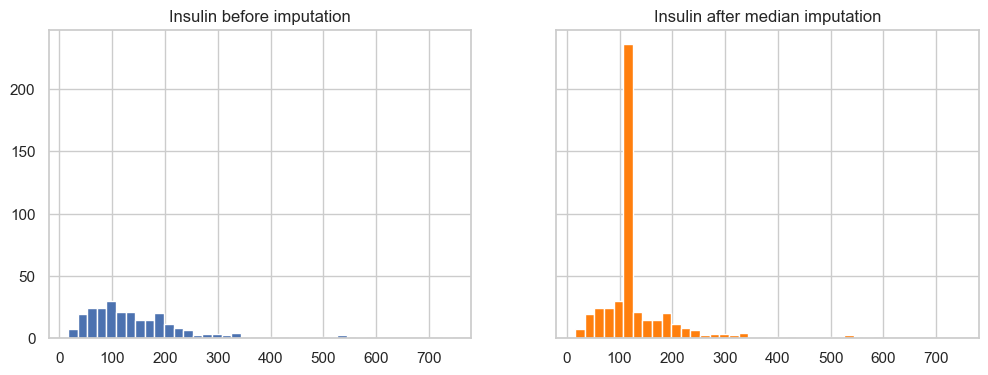

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].hist(X_train["Insulin"].dropna(), bins=40)
axes[0].set_title("Insulin before imputation")

axes[1].hist(X_train_imp["Insulin"], bins=40, color="tab:orange")
axes[1].set_title("Insulin after median imputation")

plt.show()

<div dir="rtl">

یک **ستون غول‌آسا** روی میانه ظاهر شد: نیمی از بیماران حالا دقیقاً یک مقدار انسولین دارند! این هزینهٔ پر کردن تعداد زیادی جای خالی است.

### ۴.۲ هم‌مقیاس کردن با `StandardScaler`

بازهٔ ستون‌ها را ببینید:

</div>

In [ ]:
X_train_imp.describe().loc[["mean", "std", "min", "max"]].round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
mean,3.78,121.81,71.86,29.60,137.85,32.47,0.48,33.10
std,3.31,29.26,12.32,9.18,78.98,6.88,0.34,11.73
min,0.00,56.00,24.00,7.00,16.00,18.20,0.08,21.00
max,14.00,197.00,114.00,99.00,744.00,67.10,2.33,81.00


<div dir="rtl">

`Insulin` در حد **صدها** است و `DiabetesPedigreeFunction` حدود **۰٫۵**!

چرا این برای پرسپترون مشکل است؟ قانون به‌روزرسانی پرسپترون (بخش ۵) این است: «خودِ <span dir="ltr">$\mathbf{x}$</span> را به <span dir="ltr">$\mathbf{w}$</span> اضافه کن». پس هر ویژگی که عددهای بزرگ‌تری دارد، در هر به‌روزرسانی سهم بیشتری در تغییر <span dir="ltr">$\mathbf{w}$</span> می‌گیرد، **فقط به خاطر واحد اندازه‌گیری‌اش**، نه به خاطر اهمیتش. در بخش ۷ این را با آزمایش می‌بینیم.

`StandardScaler` هر ستون را به میانگین ۰ و انحراف معیار ۱ می‌برد:

</div>

$$z = \frac{x - \mu}{\sigma}$$

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train_imp)

X_train_scaled = pd.DataFrame(scaler.transform(X_train_imp), columns=features, index=X_train.index)
X_val_scaled   = pd.DataFrame(scaler.transform(X_val_imp),   columns=features, index=X_val.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test_imp),  columns=features, index=X_test.index)

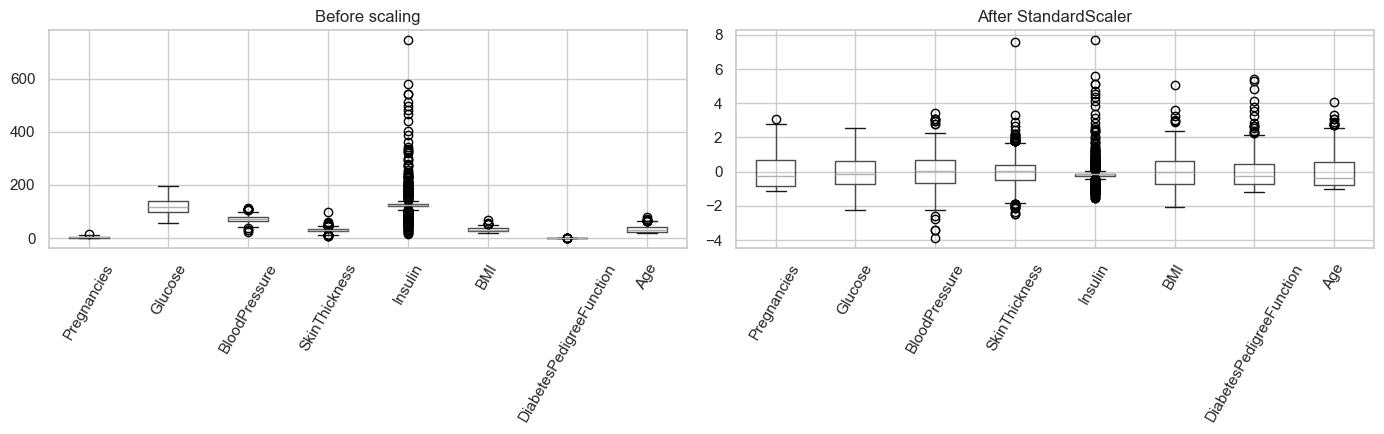

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

X_train_imp.boxplot(ax=axes[0], rot=60)
axes[0].set_title("Before scaling")

X_train_scaled.boxplot(ax=axes[1], rot=60)
axes[1].set_title("After StandardScaler")

plt.tight_layout()
plt.show()

<div dir="rtl">

قبل از scaling عملاً فقط `Insulin` دیده می‌شد؛ حالا همهٔ ویژگی‌ها در یک بازه هستند. ✅

</div>

<div dir="rtl">

## ۵. پرسپترون را از صفر می‌نویسیم

### ۵.۱ مدل

پرسپترون یک **تابع تمایز خطی** حساب می‌کند و از روی **علامتش** تصمیم می‌گیرد:

</div>

$$g(\mathbf{x}) = \mathbf{w}^T\mathbf{x} + w_0 \qquad\qquad \hat{y} = \text{sign}\big(g(\mathbf{x})\big) \in \{-1, +1\}$$

<div dir="rtl">

**ترفند بردار افزوده (augmented vector):** یک ویژگی ثابت ۱ به اول هر نمونه اضافه می‌کنیم. آن‌وقت بایاس <span dir="ltr">$w_0$</span> هم یک وزن معمولی می‌شود و فرمول ساده‌تر می‌شود:

</div>

$$\tilde{\mathbf{x}} = [1, x_1, \dots, x_d] \qquad \tilde{\mathbf{w}} = [w_0, w_1, \dots, w_d] \qquad g(\mathbf{x}) = \tilde{\mathbf{w}}^T\tilde{\mathbf{x}}$$

<div dir="rtl">

از این‌جا به بعد، مثل اسلایدها، علامت مَد (~) را نمی‌نویسیم و <span dir="ltr">$\mathbf{x}$</span> و <span dir="ltr">$\mathbf{w}$</span> همیشه بردارهای افزوده‌اند.

سه تابع کوچک می‌نویسیم:

</div>

In [ ]:
def add_bias(X):
    # the augmented-vector trick: put a column of ones in front of X
    ones = np.ones((len(X), 1))
    return np.hstack([ones, X])


def predict(w, X):
    # +1 if w.x >= 0, otherwise -1   (X must already contain the bias column)
    return np.where(X @ w >= 0, 1, -1)


def error_rate(w, X, y):
    # fraction of misclassified samples (the 0-1 loss, averaged)
    return np.mean(predict(w, X) != y)

In [ ]:
# a tiny check: two samples with two features each
toy = np.array([[2.0, 3.0],
                [4.0, 5.0]])
add_bias(toy)

array([[1., 2., 3.],
       [1., 4., 5.]])

<div dir="rtl">

### ۵.۲ قانون یادگیری

در اسلایدها دیدیم که «تعداد خطاها» (0-1 loss) تقریباً همه‌جا گرادیان صفر دارد و نمی‌شود کمینه‌اش کرد. برای همین پرسپترون این **تابع هزینه** را کمینه می‌کند که فقط نمونه‌های اشتباه (<span dir="ltr">$\mathcal{M}$</span>) در آن سهم دارند:

</div>

$$J_p(\mathbf{w}) = \sum_{i \in \mathcal{M}} -y^{(i)}\,\mathbf{w}^T\mathbf{x}^{(i)}$$

<div dir="rtl">

یک قدم گرادیان کاهشی روی **یک** نمونهٔ اشتباه همان قانون معروف پرسپترون است:

</div>

$$\mathbf{w} \leftarrow \mathbf{w} + \eta\, y^{(i)}\, \mathbf{x}^{(i)}$$

<div dir="rtl">

به زبان ساده: اگر یک بیمار دیابتی (<span dir="ltr">$y=+1$</span>) را سالم تشخیص دادیم، <span dir="ltr">$\mathbf{x}$</span> او را به <span dir="ltr">$\mathbf{w}$</span> **اضافه** می‌کنیم تا امتیازش بالا برود؛ اگر یک فرد سالم را دیابتی تشخیص دادیم، <span dir="ltr">$\mathbf{x}$</span> او را **کم** می‌کنیم.

الگوریتم کامل (single-sample perceptron):

</div>

<pre dir="ltr">
w ← 0
repeat   (one pass over all the data = one epoch)
    for every sample i, in random order:
        if y⁽ⁱ⁾ · wᵀx⁽ⁱ⁾ ≤ 0:            # misclassified (or exactly on the boundary)
            w ← w + η · y⁽ⁱ⁾ · x⁽ⁱ⁾
until an epoch makes no mistakes   (or we reach the maximum number of epochs)
</pre>

<div dir="rtl">

همین را به پایتون ترجمه می‌کنیم. تابع ما سه چیز برمی‌گرداند: وزن‌های نهایی، خطای train بعد از هر epoch و تعداد کل به‌روزرسانی‌ها.
`seed` ترتیب تصادفی نمونه‌ها را ثابت می‌کند تا نتیجه هر بار تکرار شود.

</div>

In [ ]:
def perceptron(X, y, n_epochs=100, lr=1.0, seed=0):
    rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1])
    errors = []          # training error after each epoch
    n_updates = 0

    for epoch in range(n_epochs):
        mistakes = 0
        for i in rng.permutation(len(y)):          # visit the samples in a random order
            if y[i] * (X[i] @ w) <= 0:             # misclassified
                w = w + lr * y[i] * X[i]           # the perceptron update
                mistakes += 1
        n_updates += mistakes
        errors.append(error_rate(w, X, y))
        if mistakes == 0:                          # a full epoch without mistakes: done!
            break

    return w, errors, n_updates

<div dir="rtl">

### ۵.۳ امتحان روی یک دادهٔ جدایی‌پذیر

قبل از سراغ بیماران رفتن، الگوریتم را جایی امتحان می‌کنیم که **می‌دانیم** یک خط کامل وجود دارد.
۱۰۰ نقطهٔ تصادفی می‌سازیم و برچسبشان را با یک خط واقعی معلوم <span dir="ltr">$0.5 + x_1 - x_2 = 0$</span> تعیین می‌کنیم. نقطه‌هایی را که به این خط نزدیک‌تر از `gap` هستند حذف می‌کنیم تا یک **راهروی خالی** دور خط بماند.

</div>

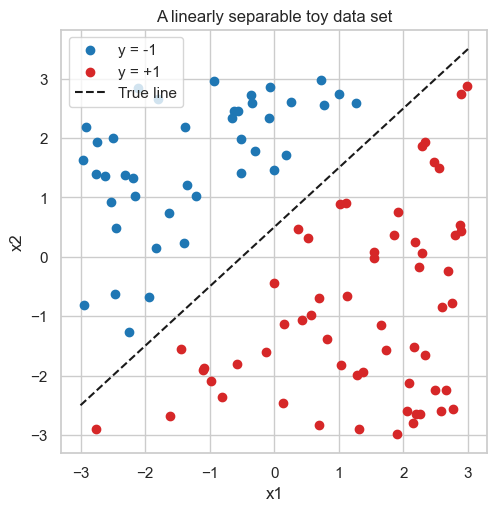

In [ ]:
w_true = np.array([0.5, 1.0, -1.0])        # the true line: 0.5 + x1 - x2 = 0


def make_toy_data(gap, n=100, seed=0):
    rng = np.random.default_rng(seed)
    points = rng.uniform(-3, 3, size=(5000, 2))
    distance = add_bias(points) @ w_true / np.linalg.norm(w_true[1:])   # signed distance to the true line
    keep = np.abs(distance) > gap                                       # leave an empty corridor around the line
    X_toy = points[keep][:n]
    y_toy = np.where(distance[keep][:n] > 0, 1, -1)
    return X_toy, y_toy


X_toy, y_toy = make_toy_data(gap=0.25)
X_toy_b = add_bias(X_toy)

x1_line = np.linspace(-3, 3, 10)
plt.figure(figsize=(5.5, 5.5))
plt.scatter(X_toy[y_toy == -1, 0], X_toy[y_toy == -1, 1], color="tab:blue", label="y = -1")
plt.scatter(X_toy[y_toy == 1, 0], X_toy[y_toy == 1, 1], color="tab:red", label="y = +1")
plt.plot(x1_line, 0.5 + x1_line, "k--", label="True line")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.title("A linearly separable toy data set")
plt.show()

In [ ]:
w_toy, errors_toy, n_updates_toy = perceptron(X_toy_b, y_toy)

print("Epochs run:      ", len(errors_toy))
print("Total updates:   ", n_updates_toy)
print("Final train error:", errors_toy[-1])
print("Learned w:       ", w_toy.round(2))

Epochs run:       5
Total updates:    15
Final train error: 0.0
Learned w:        [ 5.    6.98 -6.51]


<div dir="rtl">

پرسپترون بعد از چند epoch **خطای صفر** گرفت و خودش متوقف شد. 🎉

بیایید ببینیم خط در طول یادگیری چطور جابه‌جا شده. یک ترفند ساده: چون `seed` ثابت است، `perceptron(..., n_epochs=k)` **دقیقاً** همان <span dir="ltr">$k$</span> epoch اول اجرای کامل را تکرار می‌کند. پس برای دیدن خط بعد از epoch اول، دوم و ... کافی است `n_epochs` را عوض کنیم.

برای رسم مرز تصمیم یک تابع کمکی می‌نویسیم که برای هر نقطهٔ یک شبکهٔ ریز (`meshgrid`) پیش‌بینی مدل را حساب و پس‌زمینه را رنگ می‌کند. همین تابع را در بخش ۸ برای بیماران هم استفاده می‌کنیم.

</div>

In [ ]:
def plot_boundary(ax, w, X, y, title=""):
    # colour a fine grid by the predicted class, then draw the line g(x) = 0 and the samples
    x1_grid, x2_grid = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                                   np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    grid = add_bias(np.column_stack([x1_grid.ravel(), x2_grid.ravel()]))
    grid_pred = predict(w, grid).reshape(x1_grid.shape)

    ax.contourf(x1_grid, x2_grid, grid_pred, levels=[-2, 0, 2], colors=["tab:blue", "tab:red"], alpha=0.15)
    ax.contour(x1_grid, x2_grid, grid_pred, levels=[0], colors="black")
    ax.scatter(X[y == -1, 0], X[y == -1, 1], s=12, color="tab:blue", label="y = -1")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=12, color="tab:red", label="y = +1")
    ax.set_title(title)

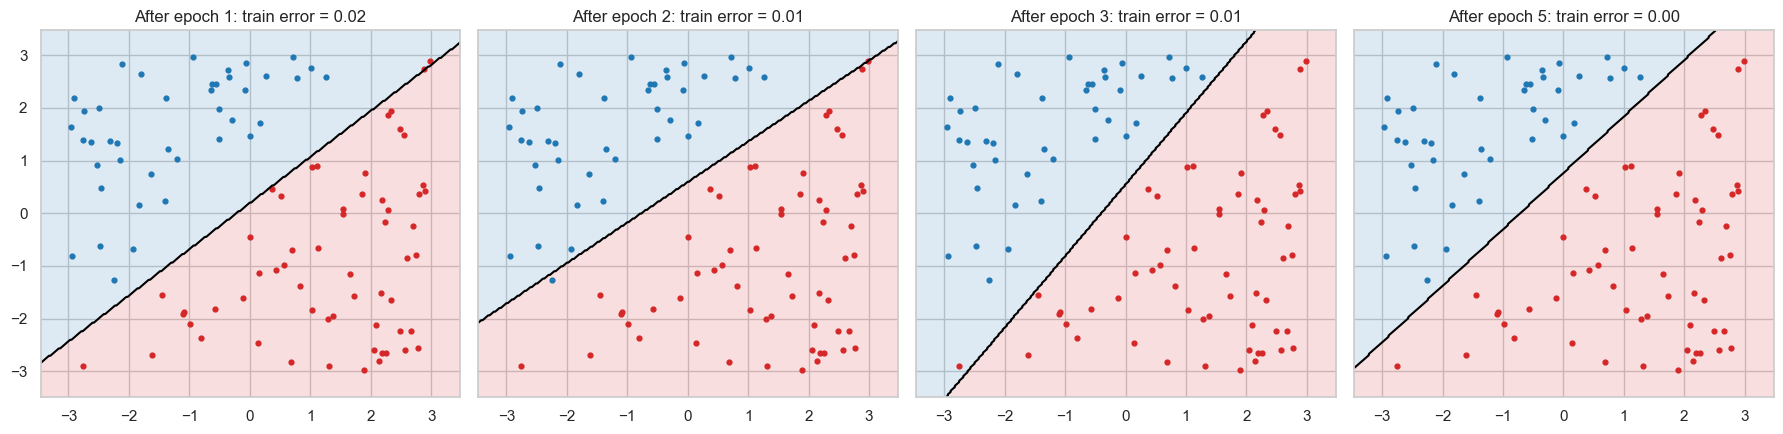

In [ ]:
epochs_to_show = [1, 2, 3, len(errors_toy)]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)

for ax, k in zip(axes, epochs_to_show):
    w_k, errors_k, _ = perceptron(X_toy_b, y_toy, n_epochs=k)
    plot_boundary(ax, w_k, X_toy, y_toy, title=f"After epoch {k}: train error = {errors_k[-1]:.2f}")

plt.tight_layout()
plt.show()

<div dir="rtl">

### ۵.۴ قضیهٔ همگرایی: پرسپترون چند بار اشتباه می‌کند؟

قضیهٔ Novikoff (اسلاید ۴۴) می‌گوید اگر یک بردار واحد <span dir="ltr">$\mathbf{w}^*$</span> همهٔ نمونه‌ها را با **حاشیهٔ (margin)** <span dir="ltr">$\gamma$</span> جدا کند و طول همهٔ نمونه‌ها حداکثر <span dir="ltr">$R$</span> باشد، پرسپترون حداکثر این تعداد به‌روزرسانی انجام می‌دهد:

</div>

$$\text{number of updates} \;\le\; \frac{R^2}{\gamma^2} \qquad\qquad \gamma = \min_i \; y^{(i)}\, \mathbf{w}^{*T}\mathbf{x}^{(i)} \qquad R = \max_i \|\mathbf{x}^{(i)}\|$$

<div dir="rtl">

چون دادهٔ مصنوعی را خودمان ساخته‌ایم، <span dir="ltr">$\mathbf{w}^*$</span> را می‌دانیم (همان خط واقعی، با طول ۱). پس می‌توانیم کران را واقعاً حساب کنیم:

</div>

In [ ]:
w_star = w_true / np.linalg.norm(w_true)               # a unit vector, as in the theorem
gamma = np.min(y_toy * (X_toy_b @ w_star))             # the margin
R = np.max(np.linalg.norm(X_toy_b, axis=1))            # the radius of the data

print("gamma:          ", round(gamma, 3))
print("R:              ", round(R, 3))
print("Bound R^2/g^2:  ", round(R**2 / gamma**2))
print("Actual updates: ", n_updates_toy)

gamma:           0.266
R:               4.269
Bound R^2/g^2:   258
Actual updates:  15


<div dir="rtl">

تعداد واقعی به‌روزرسانی‌ها **خیلی کمتر** از کران است؛ کران فقط بدترین حالت را تضمین می‌کند.

🤔 **حدس بزنید:** اگر راهروی خالی دور خط را باریک‌تر کنیم (حاشیهٔ کمتر)، کران چه می‌شود؟

</div>

In [ ]:
rows = []
for gap in [1.0, 0.5, 0.25, 0.1, 0.05]:
    X_g, y_g = make_toy_data(gap)
    X_g_b = add_bias(X_g)
    _, _, n_updates_g = perceptron(X_g_b, y_g)
    gamma_g = np.min(y_g * (X_g_b @ w_star))
    R_g = np.max(np.linalg.norm(X_g_b, axis=1))
    rows.append({"gap": gap, "gamma": round(gamma_g, 3),
                 "bound R^2/gamma^2": round(R_g**2 / gamma_g**2), "actual updates": n_updates_g})

pd.DataFrame(rows)

,gap,gamma,bound R^2/gamma^2,actual updates
0,1.00,0.946,17,1
1,0.50,0.474,68,3
2,0.25,0.266,258,15
3,0.10,0.137,966,25
4,0.05,0.051,7140,13


<div dir="rtl">

- با نصف شدن حاشیه، کران **چهار برابر** می‌شود (چون <span dir="ltr">$\gamma$</span> به توان ۲ در مخرج است). کلاس‌هایی که تقریباً به هم چسبیده‌اند ممکن است یادگیری خیلی کندی داشته باشند.
- تعداد واقعی به‌روزرسانی‌ها همیشه زیر کران است، ولی لزوماً با کران بالا و پایین نمی‌رود؛ به ترتیب نمونه‌ها و شانس هم بستگی دارد.
- این ایدهٔ «حاشیهٔ بزرگ = یادگیری آسان‌تر» انگیزهٔ اصلی **SVM** است که بعداً در درس می‌بینیم.

</div>

<div dir="rtl">

## ۶. پرسپترون روی دادهٔ واقعی بیماران

### ۶.۱ پرسپترون سرگردان

حالا سراغ بیماران برمی‌گردیم. اول ستون بایاس را اضافه می‌کنیم. `.to_numpy()` جدول `pandas` را به آرایهٔ `numpy` تبدیل می‌کند، چون توابع ما با آرایه کار می‌کنند.

</div>

In [ ]:
X_train_b = add_bias(X_train_scaled.to_numpy())
X_val_b   = add_bias(X_val_scaled.to_numpy())
X_test_b  = add_bias(X_test_scaled.to_numpy())

print(X_train_b.shape)      # 8 features + 1 bias column

(460, 9)


<div dir="rtl">

🤔 **قبل از اجرا حدس بزنید:** آیا پرسپترون این بار هم خودش متوقف می‌شود؟ (نمودار Glucose–BMI در بخش ۲ را به یاد بیاورید.)

</div>

In [ ]:
w_perc, errors_perc, n_updates_perc = perceptron(X_train_b, y_train, n_epochs=100)

print("Epochs run:          ", len(errors_perc))
print("Total updates:       ", n_updates_perc)
print("Train error, last epoch:", round(errors_perc[-1], 3))

Epochs run:           100
Total updates:        13950
Train error, last epoch: 0.287


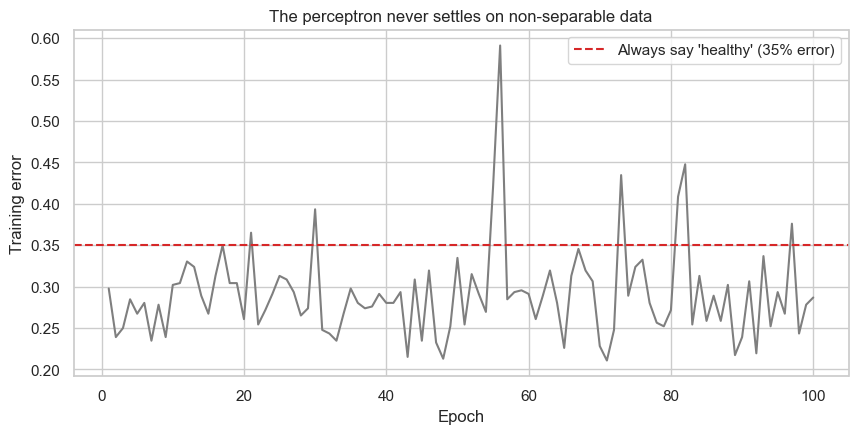

In [ ]:
plt.figure(figsize=(10, 4.5))
plt.plot(range(1, len(errors_perc) + 1), errors_perc, color="tab:gray")
plt.axhline(0.35, color="tab:red", linestyle="--", label="Always say 'healthy' (35% error)")
plt.xlabel("Epoch")
plt.ylabel("Training error")
plt.title("The perceptron never settles on non-separable data")
plt.legend()
plt.show()

<div dir="rtl">

همهٔ ۱۰۰ epoch اجرا شد و الگوریتم **هرگز** متوقف نشد. خطای train مدام بالا و پایین می‌پرد، گاهی حتی از مدل تنبل «همیشه سالم» هم بدتر می‌شود!

دلیلش این است که داده جدایی‌پذیر نیست: همیشه نمونه‌ای اشتباه دسته‌بندی شده و هر اصلاحی ممکن است نمونه‌های دیگری را خراب کند. پس وزن‌هایی که در **آخرین** epoch داریم یک «قرعه‌کشی» است: ممکن است خوب باشند، ممکن است بد.

### ۶.۲ الگوریتم Pocket: بهترین را در جیبت نگه دار!

ایدهٔ Gallant (۱۹۹۰) خیلی ساده است: همان پرسپترون معمولی را اجرا کن، ولی بهترین <span dir="ltr">$\mathbf{w}$</span> که تا الان دیده‌ای (کمترین خطای train) را در «جیب» نگه دار و در پایان آن را برگردان.

</div>

<pre dir="ltr">
w ← 0,   w_pocket ← w
for each epoch:
    for every sample i, in random order:
        if y⁽ⁱ⁾ · wᵀx⁽ⁱ⁾ ≤ 0:
            w ← w + η · y⁽ⁱ⁾ · x⁽ⁱ⁾                      # normal perceptron step
            if train_error(w) < train_error(w_pocket):
                w_pocket ← w                             # a new best: put it in the pocket
return w_pocket
</pre>

In [ ]:
def pocket(X, y, n_epochs=100, lr=1.0, seed=0):
    rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1])
    best_w = w.copy()
    best_error = error_rate(w, X, y)
    errors = []          # error of the current w after each epoch
    best_errors = []     # error of the pocket w after each epoch

    for epoch in range(n_epochs):
        for i in rng.permutation(len(y)):
            if y[i] * (X[i] @ w) <= 0:
                w = w + lr * y[i] * X[i]              # normal perceptron step
                current_error = error_rate(w, X, y)
                if current_error < best_error:        # better than the one in our pocket?
                    best_w = w.copy()
                    best_error = current_error
        errors.append(error_rate(w, X, y))
        best_errors.append(best_error)

    return best_w, errors, best_errors

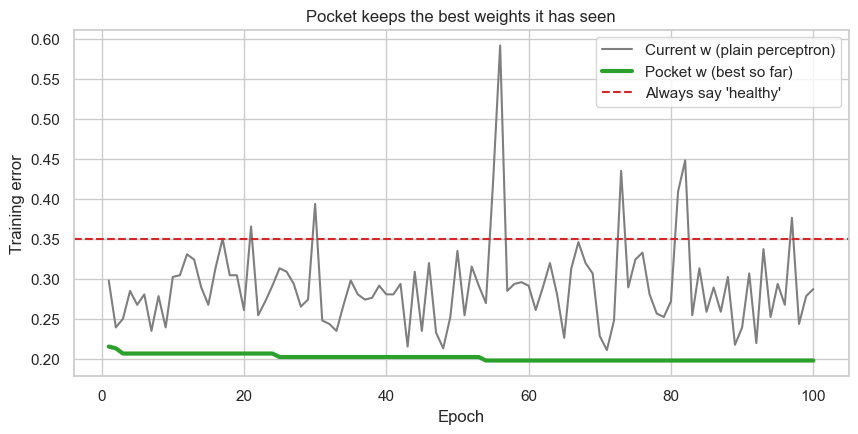

In [ ]:
w_pocket, errors_current, errors_pocket = pocket(X_train_b, y_train, n_epochs=100)

plt.figure(figsize=(10, 4.5))
plt.plot(range(1, 101), errors_current, color="tab:gray", label="Current w (plain perceptron)")
plt.plot(range(1, 101), errors_pocket, color="tab:green", linewidth=3, label="Pocket w (best so far)")
plt.axhline(0.35, color="tab:red", linestyle="--", label="Always say 'healthy'")
plt.xlabel("Epoch")
plt.ylabel("Training error")
plt.title("Pocket keeps the best weights it has seen")
plt.legend()
plt.show()

<div dir="rtl">

خط خاکستری همان پرسپترون سرگردان است، ولی خط سبز **هرگز بالا نمی‌رود**: Pocket فقط وقتی جیبش را عوض می‌کند که <span dir="ltr">$\mathbf{w}$</span> بهتری پیدا کند.

💰 **هزینه:** بعد از هر به‌روزرسانی، Pocket خطا را روی **کل** دادهٔ train حساب می‌کند؛ پس از پرسپترون معمولی کندتر است. برای ۴۶۰ بیمار این اصلاً مهم نیست.

مقایسهٔ دو مدل روی train و validation:

</div>

In [ ]:
pd.DataFrame({
    "train error": [error_rate(w_perc, X_train_b, y_train), error_rate(w_pocket, X_train_b, y_train)],
    "validation error": [error_rate(w_perc, X_val_b, y_val), error_rate(w_pocket, X_val_b, y_val)],
}, index=["Perceptron (last epoch)", "Pocket"]).round(3)

,train error,validation error
Perceptron (last epoch),0.287,0.325
Pocket,0.198,0.234


<div dir="rtl">

Pocket هم روی train و هم روی validation بهتر است. 👏

</div>

<div dir="rtl">

## ۷. دو آزمایش جالب

### ۷.۱ نرخ یادگیری <span dir="ltr">$\eta$</span> مهم نیست!

🤔 **حدس بزنید:** اگر <span dir="ltr">$\eta$</span> را از ۰٫۰۱ به ۱۰۰ ببریم، خطای پرسپترون چقدر تغییر می‌کند؟

</div>

In [ ]:
for lr in [0.01, 1, 100]:
    w_lr, errors_lr, _ = perceptron(X_train_b, y_train, n_epochs=20, lr=lr)
    w_direction = w_lr / np.linalg.norm(w_lr)
    print(f"lr = {lr:6}:  train error = {errors_lr[-1]:.3f}   first 3 weights of w/|w| = {w_direction[:3].round(3)}")

lr =   0.01:  train error = 0.261   first 3 weights of w/|w| = [-0.234  0.008  0.444]
lr =      1:  train error = 0.261   first 3 weights of w/|w| = [-0.234  0.008  0.444]
lr =    100:  train error = 0.261   first 3 weights of w/|w| = [-0.234  0.008  0.444]


<div dir="rtl">

**دقیقاً یکسان!** چرا؟ وقتی از <span dir="ltr">$\mathbf{w} = \mathbf{0}$</span> شروع کنیم، هر <span dir="ltr">$\mathbf{w}$</span> مجموعی از جمله‌های <span dir="ltr">$\eta\, y\, \mathbf{x}$</span> است. پس <span dir="ltr">$\eta$</span> فقط **طول** <span dir="ltr">$\mathbf{w}$</span> را بزرگ یا کوچک می‌کند و **جهتش** (یعنی خود مرز تصمیم) را عوض نمی‌کند. مرز <span dir="ltr">$\mathbf{w}^T\mathbf{x} = 0$</span> با <span dir="ltr">$5\mathbf{w}^T\mathbf{x} = 0$</span> فرقی ندارد (اسلاید ۴۵).
پس برخلاف رگرسیون با گرادیان کاهشی، برای پرسپترون لازم نیست <span dir="ltr">$\eta$</span> را تنظیم کنیم.

### ۷.۲ ولی scaling مهم است!

همان Pocket را روی دادهٔ **scale نشده** (فقط imputed) اجرا می‌کنیم:

</div>

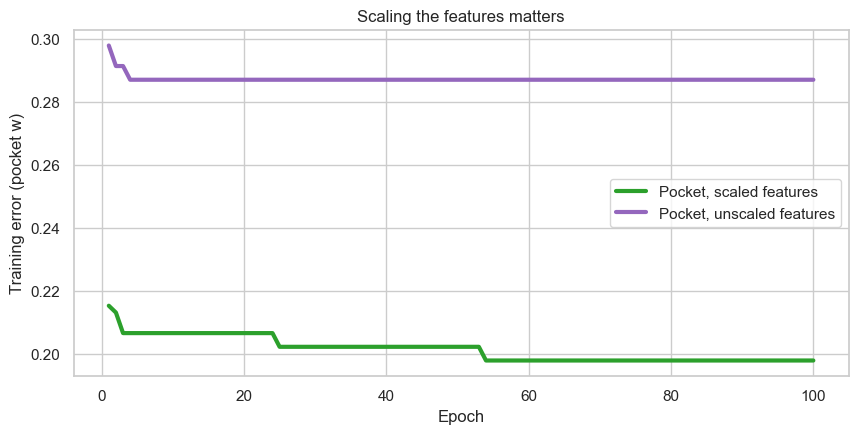

Best train error, scaled:   0.198
Best train error, unscaled: 0.287


In [ ]:
X_train_unscaled_b = add_bias(X_train_imp.to_numpy())

w_pocket_unscaled, errors_current_unscaled, errors_pocket_unscaled = pocket(X_train_unscaled_b, y_train, n_epochs=100)

plt.figure(figsize=(10, 4.5))
plt.plot(range(1, 101), errors_pocket, color="tab:green", linewidth=3, label="Pocket, scaled features")
plt.plot(range(1, 101), errors_pocket_unscaled, color="tab:purple", linewidth=3, label="Pocket, unscaled features")
plt.xlabel("Epoch")
plt.ylabel("Training error (pocket w)")
plt.title("Scaling the features matters")
plt.legend()
plt.show()

print("Best train error, scaled:  ", round(errors_pocket[-1], 3))
print("Best train error, unscaled:", round(errors_pocket_unscaled[-1], 3))

<div dir="rtl">

بدون scaling مدل به خطای خیلی بدتری می‌رسد. همان دلیلی که در بخش ۴ گفتیم: هر به‌روزرسانی خودِ <span dir="ltr">$\mathbf{x}$</span> را به <span dir="ltr">$\mathbf{w}$</span> اضافه می‌کند، پس `Insulin` (با عددهای صدتایی) و `Glucose` بر هر قدم مسلط می‌شوند و ویژگی‌هایی مثل `DiabetesPedigreeFunction` (حدود ۰٫۵) تقریباً نادیده گرفته می‌شوند. مقیاس **ویژگی‌ها** مهم است، حتی وقتی مقیاس <span dir="ltr">$\eta$</span> مهم نیست.

</div>

<div dir="rtl">

## ۸. مرزهای تصمیم

برای این‌که مرز را **ببینیم**، مدل‌ها را فقط با دو ویژگی `Glucose` و `BMI` می‌سازیم (البته scale شده).

</div>

In [ ]:
two_features = ["Glucose", "BMI"]

X_train_2 = X_train_scaled[two_features].to_numpy()
X_val_2   = X_val_scaled[two_features].to_numpy()
X_test_2  = X_test_scaled[two_features].to_numpy()

X_train_2b = add_bias(X_train_2)
X_val_2b   = add_bias(X_val_2)
X_test_2b  = add_bias(X_test_2)

<div dir="rtl">

### ۸.۱ خط پرسپترون در طول یادگیری

با همان ترفند بخش ۵.۳ (عوض کردن `n_epochs`)، خط پرسپترون را بعد از چند epoch مختلف رسم می‌کنیم:

</div>

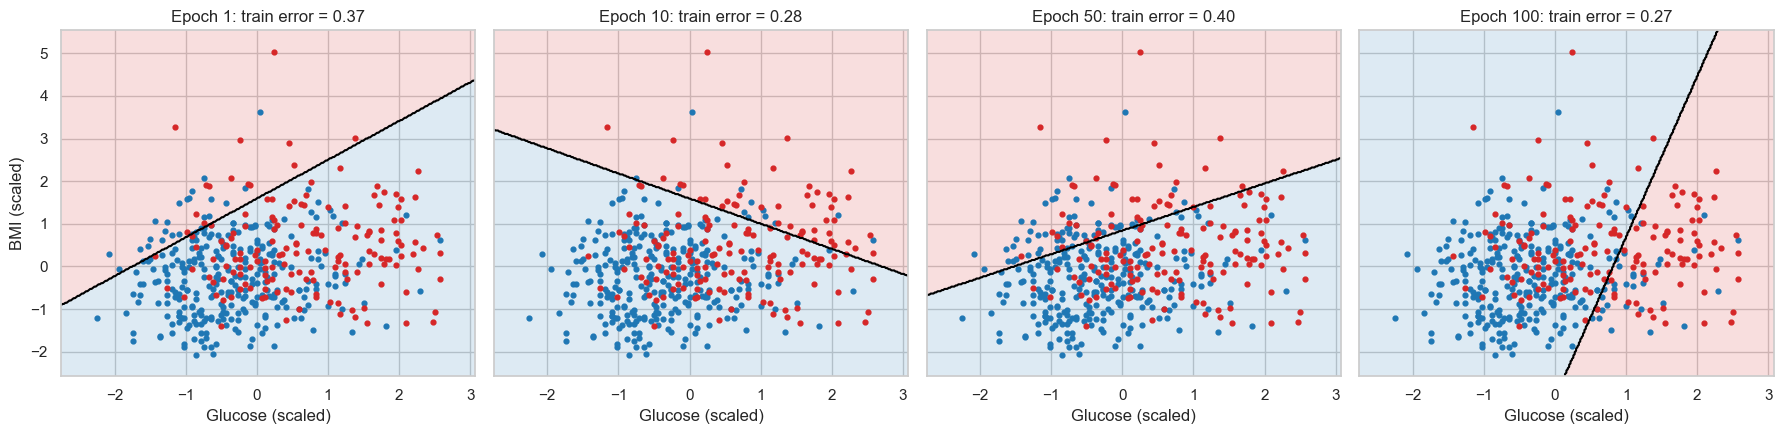

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)

for ax, k in zip(axes, [1, 10, 50, 100]):
    w_k, errors_k, _ = perceptron(X_train_2b, y_train, n_epochs=k)
    plot_boundary(ax, w_k, X_train_2, y_train, title=f"Epoch {k}: train error = {errors_k[-1]:.2f}")
    ax.set_xlabel("Glucose (scaled)")

axes[0].set_ylabel("BMI (scaled)")
plt.tight_layout()
plt.show()

<div dir="rtl">

خط مدام **می‌چرخد و جابه‌جا می‌شود** و خطا هم با آن بالا و پایین می‌رود. اجرای بیشتر لزوماً خط بهتری نمی‌دهد.

### ۸.۲ پرسپترون در برابر Pocket

</div>

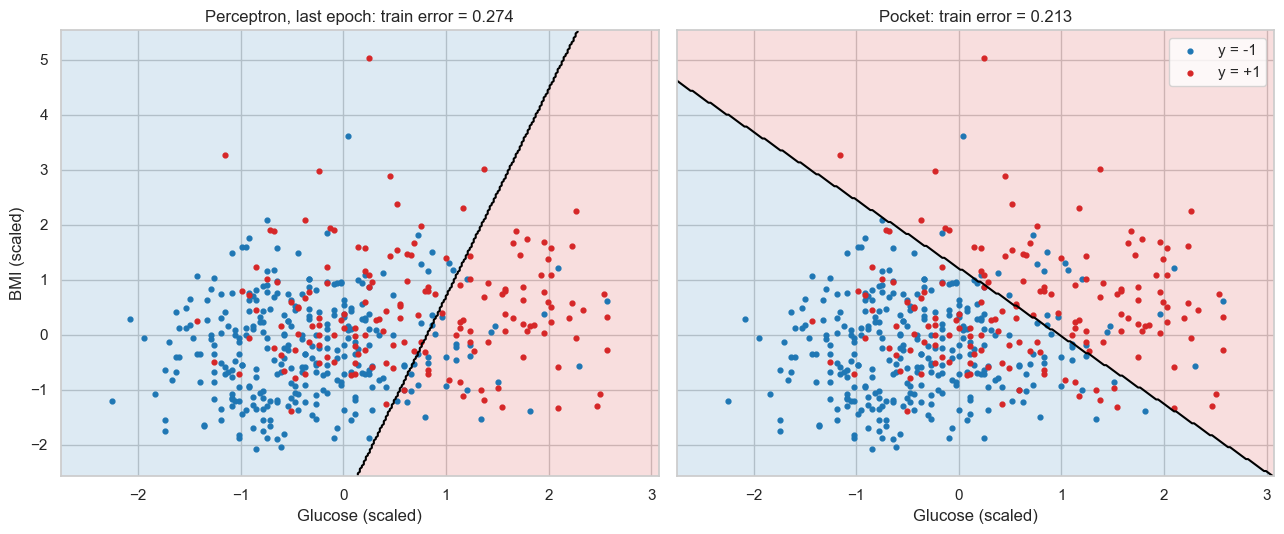

In [ ]:
w_perc_2, _, _ = perceptron(X_train_2b, y_train, n_epochs=100)
w_pocket_2, _, _ = pocket(X_train_2b, y_train, n_epochs=100)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

plot_boundary(axes[0], w_perc_2, X_train_2, y_train,
              title=f"Perceptron, last epoch: train error = {error_rate(w_perc_2, X_train_2b, y_train):.3f}")
plot_boundary(axes[1], w_pocket_2, X_train_2, y_train,
              title=f"Pocket: train error = {error_rate(w_pocket_2, X_train_2b, y_train):.3f}")

for ax in axes:
    ax.set_xlabel("Glucose (scaled)")
axes[0].set_ylabel("BMI (scaled)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
print("Pocket weights [w0, w_Glucose, w_BMI]:", w_pocket_2.round(2))

Pocket weights [w0, w_Glucose, w_BMI]: [-1.    1.02  0.82]


<div dir="rtl">

خط Pocket همان چیزی را نشان می‌دهد که از هیستوگرام‌های بخش ۱ انتظار داشتیم: بیماران با **قند خون بالا و BMI بالا** (بالا-راست) دیابتی تشخیص داده می‌شوند.
وزن `Glucose` کمی از وزن `BMI` بزرگ‌تر است (هر دو scale شده‌اند، پس قابل مقایسه‌اند): قند خون کمی مهم‌تر است. خط هم **مورب** است: هرچه BMI بیشتر باشد، با قند خون کمتری هم «دیابتی» تشخیص داده می‌شویم.

ولی خیلی از نقطه‌ها هنوز در طرف اشتباه خط هستند. با یک خط بهتر از این نمی‌شود؛ مدل‌های غیرخطی را بعداً در درس می‌بینیم.

</div>

<div dir="rtl">

## ۹. مدل چقدر خوب است؟ معیارهای ارزیابی

تا این‌جا فقط «درصد خطا» را نگاه کردیم. ولی در پزشکی **نوع** خطا هم مهم است:
فرستادن یک فرد سالم برای آزمایش‌های بیشتر (هشدار اشتباه) خیلی کم‌هزینه‌تر از **ندیدن** یک بیمار دیابتی است!

### ۹.۱ ماتریس درهم‌ریختگی (Confusion Matrix)

<div dir="ltr">

| | مدل گفت: سالم (۱-) | مدل گفت: دیابتی (۱+) |
|---|---|---|
| **واقعاً سالم** | **TN**<br>درست گفتیم سالم است | **FP**<br>هشدار اشتباه |
| **واقعاً دیابتی** | **FN**<br>⚠️ بیمار را ندیدیم | **TP**<br>بیمار را درست پیدا کردیم |

</div>

(جدول را چپ‌به‌راست نوشتیم تا ترتیب ستون‌هایش با نمودار زیر یکی باشد.)

این‌جا مدل Pocket با ۸ ویژگی را روی **validation** بررسی می‌کنیم:

</div>

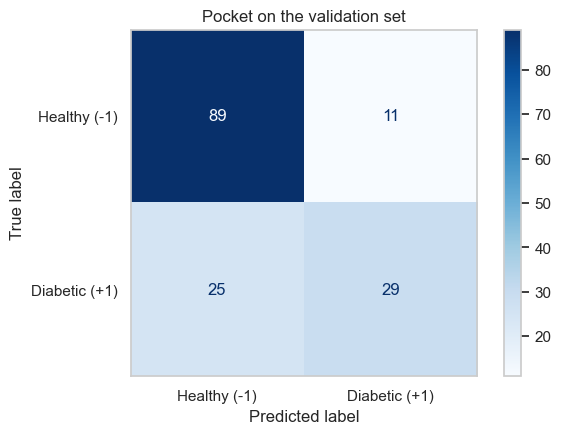

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

y_val_pred = predict(w_pocket, X_val_b)

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred, display_labels=["Healthy (-1)", "Diabetic (+1)"], cmap="Blues")
plt.title("Pocket on the validation set")
plt.grid(False)
plt.show()

<div dir="rtl">

### ۹.۲ Accuracy، Precision، Recall و F1

</div>

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} \qquad \text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

<div dir="rtl">

- **Accuracy (دقت کلی):** چند درصد کل پیش‌بینی‌ها درست بود؟
- **Precision (صحت):** از کسانی که گفتیم «دیابتی»، چند درصد واقعاً دیابتی بودند؟
- **Recall (بازیابی یا حساسیت):** از همهٔ بیماران دیابتی، چند درصد را پیدا کردیم؟ در پزشکی معمولاً **مهم‌ترین** معیار همین است.
- **F1:** میانگین همساز precision و recall؛ وقتی یکی از آن دو خیلی کم باشد، F1 هم کم می‌شود.

همه را `sklearn.metrics` آماده دارد. چون برچسب‌های ما ۱+ و ۱- هستند، `scikit-learn` به‌طور پیش‌فرض کلاس ۱+ (دیابتی) را کلاس «مثبت» می‌گیرد؛ همان چیزی که می‌خواهیم.

</div>

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy: ", round(accuracy_score(y_val, y_val_pred), 3))
print("Precision:", round(precision_score(y_val, y_val_pred), 3))
print("Recall:   ", round(recall_score(y_val, y_val_pred), 3))
print("F1:       ", round(f1_score(y_val, y_val_pred), 3))

Accuracy:  0.766


Precision: 0.725
Recall:    0.537
F1:        0.617


<div dir="rtl">

حالا همین معیارها را برای مدل تنبل «همیشه سالم» حساب کنیم:

</div>

In [ ]:
y_always_healthy = np.full(len(y_val), -1)

print("Accuracy: ", round(accuracy_score(y_val, y_always_healthy), 3))
print("Precision:", round(precision_score(y_val, y_always_healthy, zero_division=0), 3))
print("Recall:   ", round(recall_score(y_val, y_always_healthy), 3))
print("F1:       ", round(f1_score(y_val, y_always_healthy), 3))

Accuracy:  0.649
Precision: 0.0
Recall:    0.0
F1:        0.0


<div dir="rtl">

دقت ۶۵٪ به نظر بد نیست، ولی **recall صفر** است: این مدل **هیچ** بیمار دیابتی‌ای را پیدا نمی‌کند! به همین دلیل روی داده‌های نامتوازن هرگز به accuracy تنها اعتماد نکنید.
(`zero_division=0` لازم بود، چون این مدل هیچ‌وقت «دیابتی» نمی‌گوید و مخرج precision صفر می‌شود.)

### ۹.۳ منحنی ROC و AUC

پرسپترون فقط یک برچسب ۱± نمی‌دهد؛ پیش از گرفتن علامت، یک **امتیاز پیوسته** هم دارد. اگر آن را بر طول وزن‌ها تقسیم کنیم، **فاصلهٔ علامت‌دار** نمونه تا مرز تصمیم به دست می‌آید (اسلاید ۱۶). هرچه این فاصله بزرگ‌تر باشد، مدل مطمئن‌تر است:

</div>

$$d(\mathbf{x}) = \frac{w_0 + w_1 x_1 + \dots + w_d x_d}{\sqrt{w_1^2 + \dots + w_d^2}}$$

In [ ]:
def decision_score(w, X):
    # signed distance of every sample to the boundary (the bias w0 is not part of the norm)
    return X @ w / np.linalg.norm(w[1:])

<div dir="rtl">

تا الان آستانهٔ تصمیم صفر بود (<span dir="ltr">$d \ge 0$</span> یعنی دیابتی). ولی می‌توانیم آستانه را جابه‌جا کنیم. هر آستانه یک نقطه می‌دهد:

- **محور عمودی (TPR):** همان recall؛ چند درصد دیابتی‌ها را پیدا کردیم؟
- **محور افقی (FPR):** چند درصد سالم‌ها را اشتباهی دیابتی گفتیم؟

منحنی ROC همهٔ این نقطه‌ها را به هم وصل می‌کند و **AUC** مساحت زیر آن است. AUC را می‌شود این‌طور تفسیر کرد: اگر یک بیمار دیابتی و یک فرد سالم تصادفی انتخاب کنیم، با چه احتمالی مدل به بیمار امتیاز بالاتری می‌دهد؟ (۰٫۵ = حدس تصادفی، ۱ = بی‌نقص)

</div>

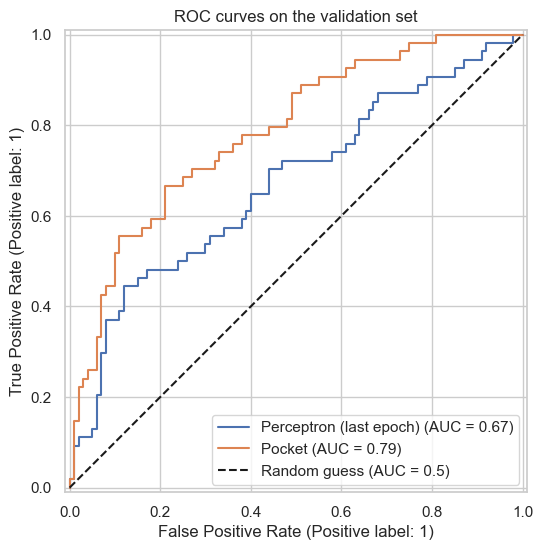

In [ ]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_val, decision_score(w_perc, X_val_b), name="Perceptron (last epoch)", ax=ax)
RocCurveDisplay.from_predictions(y_val, decision_score(w_pocket, X_val_b), name="Pocket", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
ax.set_title("ROC curves on the validation set")
ax.legend()
plt.show()

<div dir="rtl">

⚠️ **یک اشتباه رایج:** ROC-AUC را باید با **امتیاز** حساب کرد، نه با برچسب‌های نهایی. ببینید با برچسب‌ها چه می‌شود:

</div>

In [ ]:
print("AUC with the scores:         ", round(roc_auc_score(y_val, decision_score(w_pocket, X_val_b)), 3))
print("AUC with the +1/-1 labels (wrong):", round(roc_auc_score(y_val, y_val_pred), 3))

AUC with the scores:          0.786
AUC with the +1/-1 labels (wrong): 0.714


<div dir="rtl">

با برچسب‌ها فقط **یک** آستانه داریم و «منحنی» به یک نقطه و دو خط صاف تبدیل می‌شود؛ عددش هم چیز دیگری را اندازه می‌گیرد.

برای این‌که در ادامه راحت‌تر مقایسه کنیم، همهٔ معیارها را در یک تابع کوچک جمع می‌کنیم:

</div>

In [ ]:
def evaluate(y_true, y_pred, scores):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, scores),
    }


pd.DataFrame({
    "Always healthy": evaluate(y_val, y_always_healthy, np.zeros(len(y_val))),
    "Perceptron (last epoch)": evaluate(y_val, predict(w_perc, X_val_b), decision_score(w_perc, X_val_b)),
    "Pocket": evaluate(y_val, predict(w_pocket, X_val_b), decision_score(w_pocket, X_val_b)),
}).T.round(3)

,accuracy,precision,recall,F1,ROC-AUC
Always healthy,0.649,0.000,0.000,0.000,0.500
Perceptron (last epoch),0.675,0.542,0.481,0.510,0.670
Pocket,0.766,0.725,0.537,0.617,0.786


<div dir="rtl">

مدل «همیشه سالم» به همه امتیاز یکسان می‌دهد، پس AUC آن دقیقاً ۰٫۵ است: هیچ قدرت تشخیصی ندارد.
Pocket در همهٔ معیارها از پرسپترون معمولی بهتر است.

</div>

<div dir="rtl">

## ۱۰. انتخاب با Validation

یادتان هست validation مثل «آزمون آزمایشی» است؟ در نوت‌بوک قبلی با آن درجهٔ چندجمله‌ای و `alpha` را انتخاب کردیم. این‌جا با آن دو تصمیم می‌گیریم.

### ۱۰.۱ هشت ویژگی یا دو ویژگی؟

</div>

In [ ]:
pd.DataFrame({
    "Pocket (8 features)": evaluate(y_val, predict(w_pocket, X_val_b), decision_score(w_pocket, X_val_b)),
    "Pocket (Glucose + BMI)": evaluate(y_val, predict(w_pocket_2, X_val_2b), decision_score(w_pocket_2, X_val_2b)),
}).T.round(3)

,accuracy,precision,recall,F1,ROC-AUC
Pocket (8 features),0.766,0.725,0.537,0.617,0.786
Pocket (Glucose + BMI),0.786,0.769,0.556,0.645,0.834


<div dir="rtl">

جالب است! روی validation، مدلی که فقط **دو** ویژگی دارد کمی **بهتر** است. پس شش ویژگی دیگر بی‌فایده‌اند؟

قبل از نتیجه گرفتن دقت کنید: تفاوت دقت دو مدل حدود ۰٫۰۲ است، یعنی فقط حدود **۳ بیمار** از ۱۵۴ نفر! با یک validation به این کوچکی، چنین تفاوتی ممکن است کاملاً شانسی باشد.

### ۱۰.۲ داوری دقیق‌تر با Cross-Validation

راه حل را از نوت‌بوک قبلی می‌شناسیم: **K-Fold Cross-Validation** روی train + validation (`X_temp`). یک تفاوت داریم: `cross_val_score` فقط با مدل‌های `scikit-learn` کار می‌کند و Pocket ما یک تابع ساده است. پس حلقه را خودمان می‌نویسیم:

- `StratifiedKFold` نسخهٔ `KFold` است که مثل `stratify` نسبت کلاس‌ها را در هر fold حفظ می‌کند.
- `cv.split(...)` در هر دور، شمارهٔ ردیف‌های train و validation همان fold را می‌دهد.
- imputer و scaler را در **هر fold از نو** و فقط روی بخش train همان fold فیت می‌کنیم. این بار برای کوتاه شدن کد، آن دو را با `make_pipeline` (از نوت‌بوک قبلی) پشت سر هم می‌چینیم.

</div>

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_temp, y_temp), start=1):
    for name, columns in [("8 features", features), ("Glucose + BMI", two_features)]:
        # imputer + scaler, fitted again on the training part of this fold only
        prep_cv = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
        X_fold_train = add_bias(prep_cv.fit_transform(X_temp.iloc[train_idx][columns]))
        X_fold_val = add_bias(prep_cv.transform(X_temp.iloc[val_idx][columns]))

        w_fold, _, _ = pocket(X_fold_train, y_temp[train_idx])
        cv_rows.append({"fold": fold, "model": name,
                        "accuracy": accuracy_score(y_temp[val_idx], predict(w_fold, X_fold_val)),
                        "ROC-AUC": roc_auc_score(y_temp[val_idx], decision_score(w_fold, X_fold_val))})

cv_results = pd.DataFrame(cv_rows)
cv_results.groupby("model")[["accuracy", "ROC-AUC"]].agg(["mean", "std"]).round(3)

accuracy        ROC-AUC       
                  mean    std    mean    std
model                                       
8 features       0.783  0.017   0.837  0.013
Glucose + BMI    0.774  0.022   0.833  0.023

<div dir="rtl">

با میانگین ۵ fold داستان برعکس شد: مدل **۸ ویژگی** کمی بهتر است. البته تفاوت میانگین‌ها از انحراف معیار (`std`) بین foldها کمتر است؛ یعنی دو مدل در واقع تقریباً هم‌سطح‌اند.
درس مهم: **یک validation کوچک می‌تواند گمراه‌کننده باشد.** نتیجهٔ cross-validation به یک تقسیم شانسی وابسته نیست، پس از این‌جا به بعد مدل **۸ ویژگی** را انتخاب می‌کنیم.

### ۱۰.۳ جابه‌جا کردن آستانهٔ تصمیم

recall مدل ما فقط حدود ۵۴٪ است: **نیمی از بیماران دیابتی را نمی‌بینیم!** برای یک ابزار غربالگری این کافی نیست.
راه حل ساده: آستانهٔ تصمیم را از صفر **پایین‌تر** بیاوریم تا مدل راحت‌تر بگوید «دیابتی». قیمتش هشدارهای اشتباه بیشتر (precision کمتر) است.

برای آستانه‌های مختلف روی validation معیارها را حساب می‌کنیم. (این کار را روی test انجام نمی‌دهیم، چون انتخاب آستانه هم نوعی «یادگیری» است!)

</div>

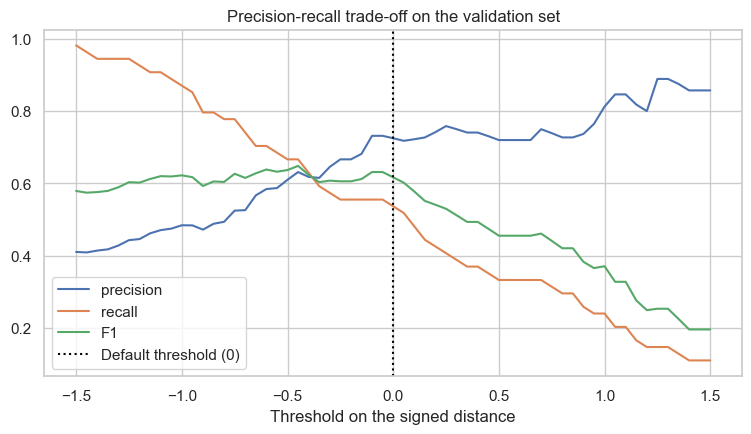

In [ ]:
val_scores = decision_score(w_pocket, X_val_b)
thresholds = np.round(np.arange(-1.5, 1.51, 0.05), 2)

rows = []
for t in thresholds:
    y_pred_t = np.where(val_scores >= t, 1, -1)
    rows.append({"threshold": t,
                 "precision": precision_score(y_val, y_pred_t, zero_division=0),
                 "recall": recall_score(y_val, y_pred_t),
                 "F1": f1_score(y_val, y_pred_t)})

threshold_table = pd.DataFrame(rows)

threshold_table.plot(x="threshold", y=["precision", "recall", "F1"], figsize=(9, 4.5))
plt.axvline(0, color="black", linestyle=":", label="Default threshold (0)")
plt.xlabel("Threshold on the signed distance")
plt.title("Precision-recall trade-off on the validation set")
plt.legend()
plt.show()

<div dir="rtl">

با پایین آمدن آستانه recall بالا می‌رود و precision پایین می‌آید: یک **بده‌بستان (trade-off)**.

فرض کنید پزشکان گفته‌اند: «حداقل ۷۵٪ بیماران دیابتی باید پیدا شوند.» از بین آستانه‌هایی که این شرط را روی validation برآورده می‌کنند، **بزرگ‌ترین** را انتخاب می‌کنیم تا هشدار اشتباه تا حد ممکن کم بماند:

</div>

In [ ]:
good_recall = threshold_table[threshold_table["recall"] >= 0.75]
best_threshold = good_recall["threshold"].max()

print("Chosen threshold:", best_threshold)
threshold_table[threshold_table["threshold"] == best_threshold].round(3)

Chosen threshold: -0.75


,threshold,precision,recall,F1
15,-0.75,0.525,0.778,0.627


<div dir="rtl">

## ۱۱. مقایسه با `Perceptron` آمادهٔ `scikit-learn`

`scikit-learn` هم یک پرسپترون آماده دارد. ببینیم با پیاده‌سازی ما چه فرقی دارد:

</div>

In [ ]:
from sklearn.linear_model import Perceptron

sk_perceptron = Perceptron(random_state=0)
sk_perceptron.fit(X_train_scaled, y_train)

print("Epochs run:", sk_perceptron.n_iter_)
print("Bias w0:   ", sk_perceptron.intercept_.round(2))
print("Weights:   ", sk_perceptron.coef_.round(2))

Epochs run: 8
Bias w0:    [-5.]
Weights:    [[ 1.48  4.48  1.16  1.09  0.48 -0.23 -0.62  4.48]]


In [ ]:
pd.DataFrame({
    "Our Pocket": evaluate(y_val, predict(w_pocket, X_val_b), decision_score(w_pocket, X_val_b)),
    "sklearn Perceptron": evaluate(y_val, sk_perceptron.predict(X_val_scaled), sk_perceptron.decision_function(X_val_scaled)),
}).T.round(3)

,accuracy,precision,recall,F1,ROC-AUC
Our Pocket,0.766,0.725,0.537,0.617,0.786
sklearn Perceptron,0.773,0.694,0.630,0.660,0.847


<div dir="rtl">

چند نکته دربارهٔ نسخهٔ `scikit-learn`:

- خودش بایاس را جدا یاد می‌گیرد (`intercept_`)، پس ستون ۱ اضافه نمی‌کنیم.
- **Pocket ندارد!** به‌جایش یک قانون توقف دارد: اگر چند epoch پشت سر هم تابع هزینه بیشتر از `tol` بهتر نشود، متوقف می‌شود. برای همین بعد از چند epoch ایستاد.
- با `early_stopping=True` بخشی از train را کنار می‌گذارد و وقتی خطای آن بخش چند epoch بهتر نشد، می‌ایستد. این هم راهی برای مهار سرگردانی پرسپترون است، ولی مثل Pocket بهترین وزن‌ها را نگه نمی‌دارد.
- `decision_function` همان امتیاز <span dir="ltr">$\mathbf{w}^T\mathbf{x} + w_0$</span> است و برای ROC-AUC از آن استفاده کردیم.

این‌جا روی validation نسخهٔ `scikit-learn` حتی کمی بهتر از Pocket ما شده است. با دادهٔ جدایی‌ناپذیر، وزن‌های پرسپترون به **لحظهٔ توقف** و **ترتیب نمونه‌ها** خیلی حساس‌اند؛ پس این تفاوت‌ها را جدی نگیرید تا روی test (یا با cross-validation) تأیید شوند.

</div>

<div dir="rtl">

## ۱۲. پرسپترون چندکلاسه: پنگوئن‌های جزایر پالمر 🐧

تا این‌جا فقط دو کلاس داشتیم. اگر <span dir="ltr">$K$</span> کلاس داشته باشیم چه؟ در اسلایدها دیدیم که یک **ماشین خطی (linear machine)** برای هر کلاس یک بردار وزن جداگانه دارد و کلاسی را انتخاب می‌کند که **بیشترین امتیاز** را بگیرد:

</div>

$$\hat{y} = \arg\max_{k}\; \mathbf{w}_k^T\mathbf{x}$$

<div dir="rtl">

اگر کلاس واقعی <span dir="ltr">$y$</span> باشد و مدل اشتباهاً <span dir="ltr">$\hat{y}$</span> را بگوید، امتیاز کلاس درست را **بالا** و امتیاز کلاس اشتباه را **پایین** می‌بریم:

</div>

$$\mathbf{w}_{y} \leftarrow \mathbf{w}_{y} + \eta\,\mathbf{x} \qquad\qquad \mathbf{w}_{\hat{y}} \leftarrow \mathbf{w}_{\hat{y}} - \eta\,\mathbf{x}$$

<div dir="rtl">

### ۱۲.۱ داده

دیتاست **Palmer Penguins** اندازه‌گیری‌های ۳۴۴ پنگوئن از سه گونه در قطب جنوب است. برای این‌که بتوانیم مرزها را رسم کنیم، فقط از دو ویژگی استفاده می‌کنیم: **طول نوک** (`bill_length_mm`) و **عمق (ضخامت) نوک** (`bill_depth_mm`).

</div>

In [ ]:
penguins = pd.read_csv("data/penguins.csv")
print(penguins.shape)
penguins.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [ ]:
print(penguins["species"].value_counts())
print()
print(penguins[["bill_length_mm", "bill_depth_mm"]].isna().sum())

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

bill_length_mm    2
bill_depth_mm     2
dtype: int64


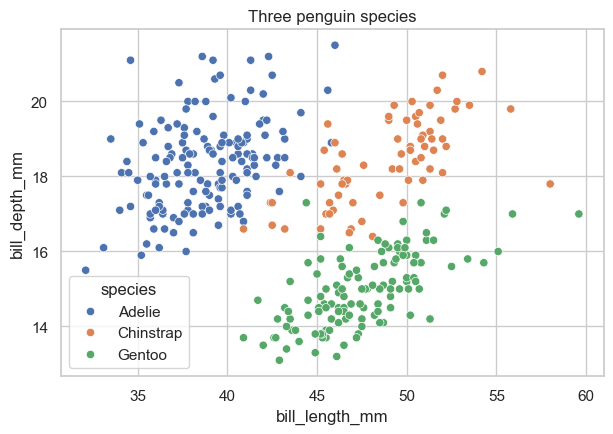

In [ ]:
sns.scatterplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", hue="species")
plt.title("Three penguin species")
plt.show()

<div dir="rtl">

سه گونه تقریباً سه ناحیهٔ جدا دارند، ولی Adelie و Chinstrap در لبه‌ها کمی روی هم افتاده‌اند. دو ردیف هم جای خالی دارند، پس دوباره به imputation نیاز داریم.

مراحل پیش‌پردازش را مثل بخش ۱۰.۲ با `make_pipeline` زنجیر می‌کنیم تا با یک `fit_transform` روی train و یک `transform` روی test کار تمام شود.
این‌جا چیزی را تنظیم نمی‌کنیم، پس فقط train و test لازم داریم (۷۰٪ / ۳۰٪). گونه‌ها را هم به عددهای ۰، ۱ و ۲ تبدیل می‌کنیم تا شمارهٔ ستون وزن‌ها باشند.

</div>

In [ ]:
penguin_features = ["bill_length_mm", "bill_depth_mm"]
species_names = ["Adelie", "Chinstrap", "Gentoo"]

Xp = penguins[penguin_features]
yp = penguins["species"].map({"Adelie": 0, "Chinstrap": 1, "Gentoo": 2}).to_numpy()

Xp_train, Xp_test, yp_train, yp_test = train_test_split(Xp, yp, test_size=0.3, random_state=42, stratify=yp)

prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
Xp_train_s = prep.fit_transform(Xp_train)      # fit on train only
Xp_test_s = prep.transform(Xp_test)

Xp_train_b = add_bias(Xp_train_s)
Xp_test_b = add_bias(Xp_test_s)
print(Xp_train_b.shape, Xp_test_b.shape)

(240, 3) (104, 3)


<div dir="rtl">

### ۱۲.۲ پیاده‌سازی

وزن‌ها این بار یک **ماتریس** <span dir="ltr">$W$</span> هستند: هر **ستون** وزن‌های یک کلاس است. پس `X[i] @ W` برای نمونهٔ <span dir="ltr">$i$</span> سه امتیاز می‌دهد و `np.argmax` شمارهٔ بزرگ‌ترین را برمی‌گرداند.

</div>

In [ ]:
def multiclass_perceptron(X, y, n_classes, n_epochs=50, lr=1.0, seed=0):
    rng = np.random.default_rng(seed)
    W = np.zeros((X.shape[1], n_classes))     # one column of weights per class
    errors = []

    for epoch in range(n_epochs):
        mistakes = 0
        for i in rng.permutation(len(y)):
            y_hat = np.argmax(X[i] @ W)                   # the class with the highest score
            if y_hat != y[i]:
                W[:, y[i]] = W[:, y[i]] + lr * X[i]       # push the true class up
                W[:, y_hat] = W[:, y_hat] - lr * X[i]     # push the wrong class down
                mistakes += 1
        errors.append(np.mean(np.argmax(X @ W, axis=1) != y))
        if mistakes == 0:
            break

    return W, errors

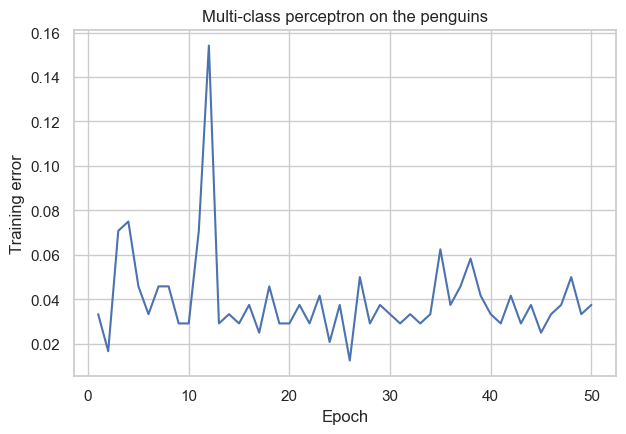

Weights (rows: bias, bill length, bill depth; columns: classes)


,Adelie,Chinstrap,Gentoo
bias,2.00,4.00,-6.00
bill_length,-7.51,-0.66,8.17
bill_depth,10.91,5.93,-16.84


In [ ]:
W, errors_mc = multiclass_perceptron(Xp_train_b, yp_train, n_classes=3, n_epochs=50)

plt.plot(range(1, len(errors_mc) + 1), errors_mc)
plt.xlabel("Epoch")
plt.ylabel("Training error")
plt.title("Multi-class perceptron on the penguins")
plt.show()

print("Weights (rows: bias, bill length, bill depth; columns: classes)")
pd.DataFrame(W, index=["bias", "bill_length", "bill_depth"], columns=species_names).round(2)

<div dir="rtl">

پرسپترون چندکلاسه هم تا آخر ۵۰ epoch **متوقف نشد**: چند پنگوئن Adelie و Chinstrap در لبه‌ها روی هم افتاده‌اند و داده کاملاً جدایی‌پذیر نیست. خطا بیشتر وقت‌ها فقط چند درصد است، ولی هر از گاهی بالا می‌پرد؛ همان رفتار سرگردان پرسپترون دودویی روی دادهٔ جدایی‌ناپذیر.

جدول وزن‌ها هم معنی دارد: ستون Gentoo برای طول نوک وزن **مثبت** و برای عمق نوک وزن **خیلی منفی** دارد؛ یعنی نوک **بلند و باریک**. برای Adelie برعکس است: نوک **کوتاه و ضخیم**.

### ۱۲.۳ نواحی تصمیم

این بار سه رنگ داریم: هر نقطه از صفحه به کلاسی تعلق دارد که بیشترین امتیاز را بگیرد. مرز بین هر دو کلاس جایی است که امتیازهایشان برابر شود (<span dir="ltr">$\mathbf{w}_i^T\mathbf{x} = \mathbf{w}_j^T\mathbf{x}$</span>).

</div>

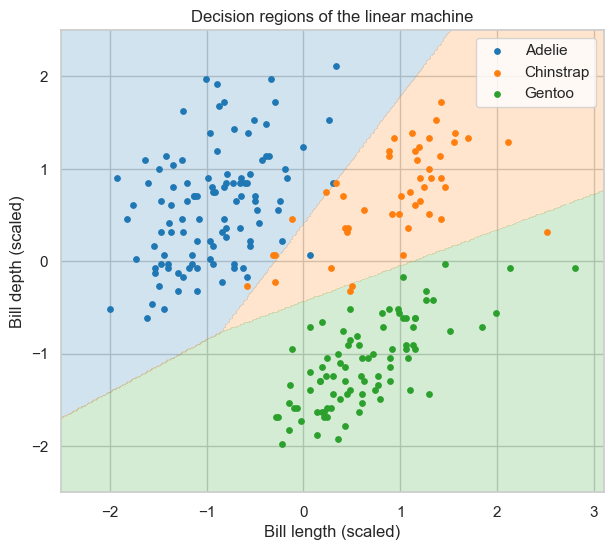

In [ ]:
x1_grid, x2_grid = np.meshgrid(np.linspace(-2.5, 3.1, 300), np.linspace(-2.5, 2.5, 300))
grid = add_bias(np.column_stack([x1_grid.ravel(), x2_grid.ravel()]))
grid_class = np.argmax(grid @ W, axis=1).reshape(x1_grid.shape)

colors = ["tab:blue", "tab:orange", "tab:green"]
plt.figure(figsize=(7, 6))
plt.contourf(x1_grid, x2_grid, grid_class, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors, alpha=0.2)
for k in range(3):
    plt.scatter(Xp_train_s[yp_train == k, 0], Xp_train_s[yp_train == k, 1], s=15, color=colors[k], label=species_names[k])
plt.xlabel("Bill length (scaled)")
plt.ylabel("Bill depth (scaled)")
plt.title("Decision regions of the linear machine")
plt.legend()
plt.show()

<div dir="rtl">

### ۱۲.۴ ارزیابی روی test

برای چند کلاس، `classification_report` همهٔ معیارها را برای **هر کلاس** جداگانه گزارش می‌دهد:

</div>

              precision    recall  f1-score   support

      Adelie       0.98      1.00      0.99        46
   Chinstrap       0.86      0.90      0.88        21
      Gentoo       0.97      0.92      0.94        37

    accuracy                           0.95       104
   macro avg       0.94      0.94      0.94       104
weighted avg       0.95      0.95      0.95       104



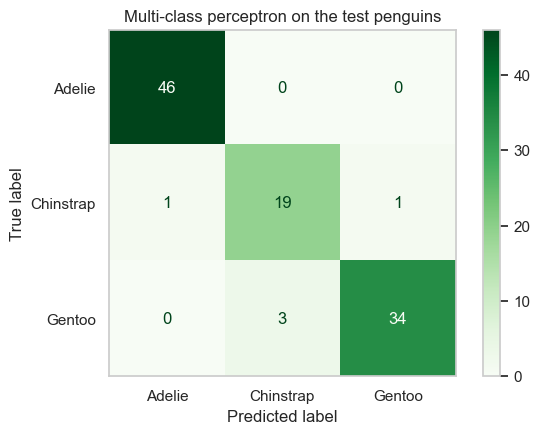

In [ ]:
from sklearn.metrics import classification_report

yp_pred = np.argmax(Xp_test_b @ W, axis=1)

print(classification_report(yp_test, yp_pred, target_names=species_names))

ConfusionMatrixDisplay.from_predictions(yp_test, yp_pred, display_labels=species_names, cmap="Greens")
plt.title("Multi-class perceptron on the test penguins")
plt.grid(False)
plt.show()

<div dir="rtl">

حدود ۹۵٪ پنگوئن‌های test درست دسته‌بندی شدند. بیشتر اشتباه‌ها مربوط به **Chinstrap** است: کلاسی که کمترین نمونه را دارد و در لبه‌ها با دو گونهٔ دیگر هم‌پوشانی دارد.

💡 `Perceptron` آمادهٔ `scikit-learn` هم چندکلاسه کار می‌کند، ولی با روش **یکی در برابر بقیه (One-vs-Rest)**: برای هر کلاس یک پرسپترون دودویی جدا می‌سازد (اسلاید ۵۰). نه یک ماشین خطی مثل نسخهٔ ما.

</div>

In [ ]:
sk_multi = Perceptron(random_state=0)
sk_multi.fit(Xp_train_s, yp_train)

print("Number of binary perceptrons (One-vs-Rest):", sk_multi.coef_.shape[0])
print("Test accuracy, sklearn One-vs-Rest:   ", round(sk_multi.score(Xp_test_s, yp_test), 3))
print("Test accuracy, our linear machine:    ", round(accuracy_score(yp_test, yp_pred), 3))

Number of binary perceptrons (One-vs-Rest): 3
Test accuracy, sklearn One-vs-Rest:    0.913
Test accuracy, our linear machine:     0.952


<div dir="rtl">

در این مسئله ماشین خطی ما از One-vs-Rest بهتر عمل کرد، ولی این همیشه صادق نیست. ناحیه‌های «بی‌صاحب» یا «دعوایی» اسلاید ۵۱ هم در هیچ‌کدام پیش نمی‌آید، چون `scikit-learn` هم در پایان کلاسی را انتخاب می‌کند که بیشترین امتیاز را بگیرد (`argmax`). تفاوت در **آموزش** است: در One-vs-Rest هر پرسپترون جداگانه و بی‌خبر از بقیه یاد می‌گیرد، ولی در ماشین خطی همهٔ وزن‌ها با هم و برای یک هدف مشترک به‌روز می‌شوند.

</div>

<div dir="rtl">

## ۱۳. لحظهٔ حقیقت: ارزیابی نهایی روی Test 🏁

به بیماران برمی‌گردیم. همهٔ مدل‌ها روی train ساخته شده‌اند و آستانه با validation انتخاب شده است. حالا **فقط یک بار** روی test ارزیابی می‌کنیم:

</div>

In [ ]:
test_scores_pocket = decision_score(w_pocket, X_test_b)

final_results = {
    "Always healthy (baseline)": evaluate(y_test, np.full(len(y_test), -1), np.zeros(len(y_test))),
    "Perceptron, last epoch": evaluate(y_test, predict(w_perc, X_test_b), decision_score(w_perc, X_test_b)),
    "sklearn Perceptron": evaluate(y_test, sk_perceptron.predict(X_test_scaled), sk_perceptron.decision_function(X_test_scaled)),
    "Pocket (Glucose + BMI)": evaluate(y_test, predict(w_pocket_2, X_test_2b), decision_score(w_pocket_2, X_test_2b)),
    "Pocket (8 features)": evaluate(y_test, predict(w_pocket, X_test_b), test_scores_pocket),
    f"Pocket, threshold {best_threshold}": evaluate(y_test, np.where(test_scores_pocket >= best_threshold, 1, -1), test_scores_pocket),
}

leaderboard = pd.DataFrame(final_results).T.round(3)
leaderboard

,accuracy,precision,recall,F1,ROC-AUC
Always healthy (baseline),0.649,0.000,0.000,0.000,0.500
"Perceptron, last epoch",0.714,0.609,0.519,0.560,0.732
sklearn Perceptron,0.721,0.622,0.519,0.566,0.773
Pocket (Glucose + BMI),0.708,0.610,0.463,0.526,0.770
Pocket (8 features),0.721,0.634,0.481,0.547,0.804
"Pocket, threshold -0.75",0.701,0.549,0.833,0.662,0.804


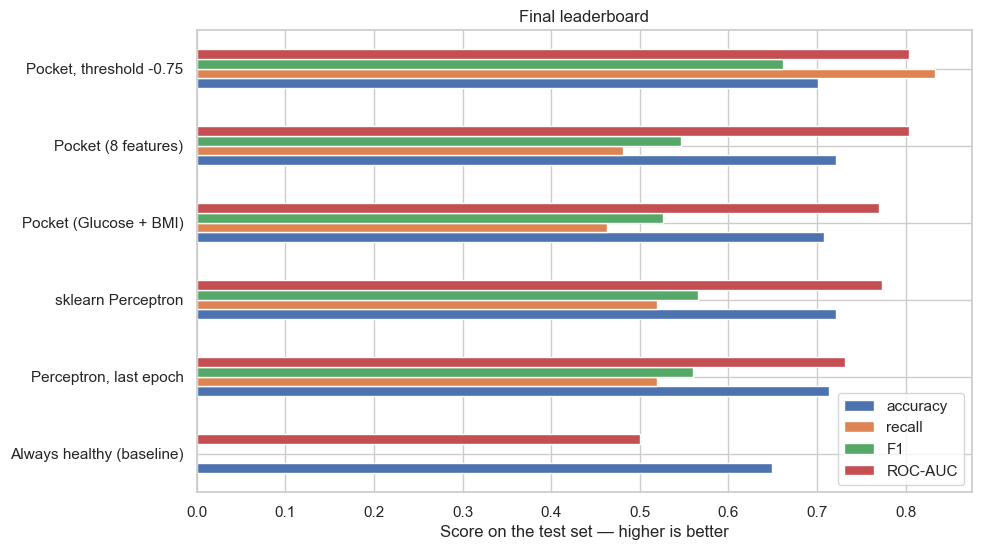

In [ ]:
leaderboard[["accuracy", "recall", "F1", "ROC-AUC"]].plot.barh(figsize=(10, 6))
plt.xlabel("Score on the test set — higher is better")
plt.title("Final leaderboard")
plt.legend(loc="lower right")
plt.show()

<div dir="rtl">

چند نکته از جدول نهایی:

- همهٔ مدل‌ها از خط پایهٔ «همیشه سالم» بهترند، ولی دقت روی test (حدود ۷۰ تا ۷۲٪) کمی **کمتر** از validation است. عادی است: validation را برای انتخاب کردن به کار بردیم و test دادهٔ کاملاً تازه است. (عدد ۷۶٪ اسلایدها روی همهٔ ۷۵۲ بیمار و با روش دیگری، یعنی رگرسیون لجستیک که بعداً در درس می‌بینیم، به دست آمده بود، نه روی یک test جدا.)
- **Pocket با ۸ ویژگی** بالاترین ROC-AUC را دارد: بهتر از بقیه بیماران را از سالم‌ها **رتبه‌بندی** می‌کند. انتخاب cross-validation (۸ ویژگی به‌جای ۲) روی test هم درست از آب درآمد.
- پرسپترون معمولی (وزن‌های آخرین epoch) ضعیف‌ترین ROC-AUC را در بین مدل‌های آموزش‌دیده دارد: همان «قرعه‌کشی» بخش ۶.
- **آستانهٔ انتخاب‌شده با validation** recall را از حدود ۴۸٪ به حدود ۸۳٪ رساند! قیمتش precision و accuracy کمتر بود. ROC-AUC آن تغییری نکرد، چون جابه‌جا کردن آستانه امتیازها را عوض نمی‌کند.
- باز هم می‌بینیم که accuracy همه‌چیز نیست: مدل آستانه‌دار دقت کمتری دارد، ولی برای غربالگری بیماری **مفیدتر** است.

</div>

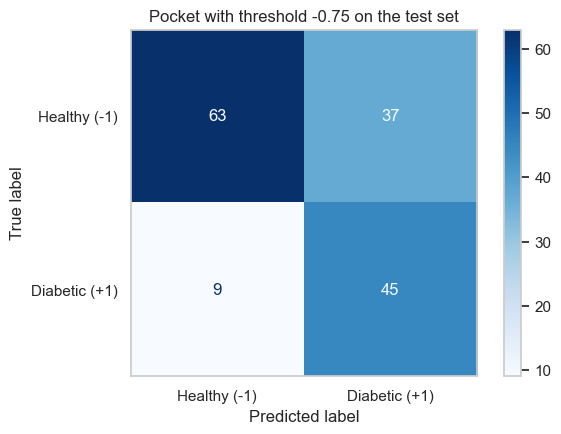

In [ ]:
y_test_final = np.where(test_scores_pocket >= best_threshold, 1, -1)

ConfusionMatrixDisplay.from_predictions(y_test, y_test_final, display_labels=["Healthy (-1)", "Diabetic (+1)"], cmap="Blues")
plt.title(f"Pocket with threshold {best_threshold} on the test set")
plt.grid(False)
plt.show()

<div dir="rtl">

از ۵۴ بیمار دیابتی test، مدل **۴۵ نفر** را پیدا کرد و فقط ۹ نفر را ندید. قیمتش ۳۷ هشدار اشتباه از ۱۰۰ فرد سالم بود.
برای یک **غربالگری اولیه**، که بعدش آزمایش‌های دقیق‌تر می‌آید، این معاملهٔ معقولی است. ولی یادتان باشد: این‌که چه مقدار هشدار اشتباه قابل قبول است تصمیمی **پزشکی** است، نه تصمیمی که مدل بگیرد! 🩺

</div>

<div dir="rtl">

## ۱۴. جمع‌بندی

| مرحله | درسی که گرفتیم |
|---|---|
| آشنایی با داده | «بدون جای خالی» همیشه یعنی «بدون دادهٔ گمشده» نیست؛ صفرهای غیرممکن را پیدا کن |
| داده‌های نامتوازن | با `stratify` تقسیم کن و همیشه مدل‌ها را با خط پایهٔ «همیشه کلاس اکثریت» مقایسه کن |
| Imputation و Scaling | `fit` فقط روی train؛ برای پرسپترون scaling واقعاً مهم است |
| پرسپترون | مدل خطی با یک قانون سادهٔ اصلاح خطا؛ روی دادهٔ جدایی‌پذیر حتماً همگرا می‌شود (حداکثر <span dir="ltr">$R^2/\gamma^2$</span> به‌روزرسانی) |
| دادهٔ جدایی‌ناپذیر | پرسپترون هرگز متوقف نمی‌شود و وزن‌های آخرش قرعه‌کشی است |
| Pocket | بهترین وزن‌ها را در جیب نگه دار؛ یک اصلاح ساده و مؤثر |
| نرخ یادگیری | وقتی از صفر شروع کنیم، <span dir="ltr">$\eta$</span> فقط طول <span dir="ltr">$\mathbf{w}$</span> را عوض می‌کند، نه مرز را |
| معیارها | accuracy روی دادهٔ نامتوازن گمراه‌کننده است؛ recall، precision، F1 و ROC-AUC را هم ببین |
| ROC-AUC | با **امتیاز** پیوسته حساب می‌شود، نه با برچسب |
| Cross-validation | یک validation کوچک ممکن است شانسی گمراه کند؛ برای مدل‌های خودمان حلقهٔ CV را دستی می‌نویسیم |
| آستانهٔ تصمیم | با جابه‌جا کردنش recall و precision را با هم معامله می‌کنیم؛ انتخابش با validation |
| چندکلاسه | یک بردار وزن برای هر کلاس و `argmax`؛ کلاس درست بالا، کلاس اشتباه پایین |

### 🏋️ تمرین‌ها

۱. **پرسپترون دسته‌ای (Batch):** نسخهٔ batch را از اسلاید ۴۱ پیاده کنید (در هر قدم مجموع <span dir="ltr">$y\,\mathbf{x}$</span> همهٔ نمونه‌های اشتباه را اضافه کنید) و منحنی خطای آن را با نسخهٔ single-sample مقایسه کنید.

۲. **شانس چقدر مهم است؟** Pocket را با `seed`های ۰ تا ۹ اجرا کنید و میانگین و انحراف معیار خطای validation را گزارش کنید.

۳. **Insulin را حذف کنید:** مدل را بدون `Insulin` و `SkinThickness` بسازید و روی validation مقایسه کنید. ارزش نگه داشتن ستونی که نصفش ساختگی است چقدر بود؟

۴. **Pocket چندکلاسه:** ایدهٔ Pocket را به `multiclass_perceptron` اضافه کنید و آن را با هر چهار ویژگی عددی پنگوئن‌ها امتحان کنید.

۵. **خود گمشدن هم اطلاعات است:** `SimpleImputer(strategy="median", add_indicator=True)` برای هر ستون ناقص یک ستون ۰/۱ «آیا گمشده بود؟» اضافه می‌کند. آیا مدل بهتر می‌شود؟

</div>